# COMP90049 Assignment 2 — Bank Marketing

## Dataset

This project uses the **Bank Marketing dataset** from the **UCI Machine Learning Repository**.

The data is related to direct marketing campaigns conducted by a Portuguese banking institution through phone calls. The prediction target is whether a client subscribes to a term deposit (`y`).

- Dataset: Bank Marketing
- Source: UCI Machine Learning Repository
- File used: `bank-additional-full.csv`
- Instances before cleaning: 41,188
- Target: `y`
  - `yes` = subscribed to a term deposit
  - `no` = did not subscribe

## Research Questions

### RQ1
**How effectively can different machine learning models predict whether a client will subscribe to a term deposit?**

RQ1 uses a broader feature set including demographic, financial, current campaign, previous campaign, and socio-economic information.

The `duration` feature is excluded because it is only known after the phone call has ended.

### RQ2
**How much does previous campaign history contribute to subscription prediction beyond customer demographic and financial information?**

RQ2 compares two feature sets:

- **Set A:** Customer demographic and financial information only.
- **Set B:** Set A plus previous campaign history.

The difference in predictive performance between Set A and Set B is used to estimate the additional predictive value of previous campaign history.

## Experimental Setup

- Exact duplicate rows are removed.
- The target is encoded as:
  - `no = 0`
  - `yes = 1`
- The original UCI row order is retained: the earliest 80% is used for training and the latest 20% for testing.
- Five expanding-window validation splits use only earlier training rows to predict later rows.
- RQ1, RQ2 Set A, and RQ2 Set B use the same train/test observations.
- Categorical features are one-hot encoded.
- Numerical features are standardised.
- Preprocessing is fitted only on the training data to avoid data leakage.

## Reading Guide

Sections 15–17 present the primary neural-network experiment using ordinary gradient descent and backpropagation.
RQ1 and RQ2 report accuracy, precision, recall, F1 and ROC-AUC; model selection uses mean validation F1.


## Team Workflow

- **Person A:** Data preparation, preprocessing, literature review, and RQ2 analysis.
- **Person B:** Classical ML models, hyperparameter tuning, evaluation, and RQ1 lead.
- **Person C:** Neural network modelling, evaluation, bibliography, and report integration.

In [1]:
# Run this once only if a required package is missing, then restart the kernel.
# %pip install pandas numpy scikit-learn matplotlib seaborn threadpoolctl
print("Required packages: pandas, numpy, scikit-learn, matplotlib, seaborn, threadpoolctl")


Required packages: pandas, numpy, scikit-learn, matplotlib, seaborn, threadpoolctl


## 1. Load Data

In [2]:
import pandas as pd

# Load the full Bank Marketing dataset
df = pd.read_csv("data/bank-additional-full.csv", sep=";")

# Preview the first five rows
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Basic Data Inspection

In [3]:
# Check dataset dimensions
print("Shape:", df.shape)

# Display all column names
print("\nColumns:")
print(df.columns.tolist())

Shape: (41188, 21)

Columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


In [4]:
# Inspect data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [5]:
# Check target class counts
print("Target counts:")
print(df["y"].value_counts())

# Check target class proportions
print("\nTarget proportions:")
print(df["y"].value_counts(normalize=True))

Target counts:
y
no     36548
yes     4640
Name: count, dtype: int64

Target proportions:
y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64


## 3. Data Quality Analysis

In [6]:
# Count standard missing values in each column
missing_counts = df.isnull().sum()

missing_counts

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [7]:
# Count "unknown" categorical values in each column
unknown_counts = (df == "unknown").sum()

# Show only columns containing unknown values
unknown_counts[unknown_counts > 0]

job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64

In [8]:
# Calculate percentage of unknown values
unknown_percent = unknown_counts[unknown_counts > 0] / len(df) * 100

unknown_percent.round(2)

job           0.80
marital       0.19
education     4.20
default      20.87
housing       2.40
loan          2.40
dtype: float64

In [9]:
# Summarise class distribution
class_distribution = pd.DataFrame({
    "count": df["y"].value_counts(),
    "percentage": df["y"].value_counts(normalize=True) * 100
})

class_distribution.round(2)

,count,percentage
y,,
no,36548,88.73
yes,4640,11.27


In [10]:
# Count exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 12


In [11]:
# Distribution of previous campaign contacts
df["previous"].value_counts().sort_index()

previous
0    35563
1     4561
2      754
3      216
4       70
5       18
6        5
7        1
Name: count, dtype: int64

In [12]:
# Distribution of previous campaign outcomes
df["poutcome"].value_counts()

poutcome
nonexistent    35563
failure         4252
success         1373
Name: count, dtype: int64

In [13]:
# Compare previous contact counts with previous campaign outcomes
pd.crosstab(df["previous"], df["poutcome"])

poutcome,failure,nonexistent,success
previous,,,
0,0,35563,0
1,3696,0,865
2,434,0,320
3,88,0,128
4,30,0,40
5,3,0,15
6,1,0,4
7,0,0,1


In [14]:
# Inspect pdays values
df["pdays"].value_counts().sort_index()

pdays
0         15
1         26
2         61
3        439
4        118
5         46
6        412
7         60
8         18
9         64
10        52
11        28
12        58
13        36
14        20
15        24
16        11
17         8
18         7
19         3
20         1
21         2
22         3
25         1
26         1
27         1
999    39673
Name: count, dtype: int64

In [15]:
# Count records using the special pdays value 999
pdays_999_count = (df["pdays"] == 999).sum()

print("Number of pdays = 999:", pdays_999_count)
print("Percentage:", round(pdays_999_count / len(df) * 100, 2), "%")

Number of pdays = 999: 39673
Percentage: 96.32 %


In [16]:
# Previous contacts exist, but pdays is still 999
previous_with_999 = (
    (df["previous"] > 0) &
    (df["pdays"] == 999)
).sum()

print("Previous > 0 and pdays = 999:", previous_with_999)

Previous > 0 and pdays = 999: 4110


In [17]:
# No previous contacts, but pdays has a recorded value
no_previous_with_pdays = (
    (df["previous"] == 0) &
    (df["pdays"] != 999)
).sum()

print("Previous = 0 and pdays != 999:", no_previous_with_pdays)

Previous = 0 and pdays != 999: 0


In [18]:
# Compare previous campaign outcome with current subscription outcome
poutcome_target = pd.crosstab(
    df["poutcome"],
    df["y"],
    normalize="index"
)

poutcome_target

y,no,yes
poutcome,,
failure,0.857714,0.142286
nonexistent,0.911678,0.088322
success,0.348871,0.651129


## 4. Remove Duplicate Rows

In [19]:
# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Confirm the updated dataset size
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (41176, 21)


In [20]:
# Confirm no duplicate rows remain
print("Remaining duplicates:", df.duplicated().sum())

Remaining duplicates: 0


## 5 Define RQ1 Feature Set

RQ1 uses a broader feature set to compare the predictive performance of different machine learning models.

The `duration` feature is excluded because it is only known after the call has ended. The original `pdays` variable is replaced by the engineered `pdays_recorded` and `pdays_clean` features.

In [21]:
# Mark whether pdays contains an actual day value
df["pdays_recorded"] = (df["pdays"] != 999).astype(int)

# Replace the sentinel value 999 with 0
df["pdays_clean"] = df["pdays"].where(df["pdays"] != 999, 0)

In [22]:
# Full feature set for RQ1 model comparison
rq1_features = [
    # Demographic and financial
    "age",
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",

    # Current campaign
    "contact",
    "month",
    "day_of_week",
    "campaign",

    # Previous campaign history
    "previous",
    "poutcome",
    "pdays_recorded",
    "pdays_clean",

    # Socio-economic context
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

# Create RQ1 feature matrix
X_rq1 = df[rq1_features].copy()

print("RQ1 feature count:", len(rq1_features))
print("RQ1 shape:", X_rq1.shape)

RQ1 feature count: 20
RQ1 shape: (41176, 20)


## 6. Define RQ2 Feature Groups

To address RQ2, two feature sets are defined:

- **Set A:** Customer demographic and financial information only.
- **Set B:** Set A plus previous campaign history.

The comparison between these two sets will be used to measure the additional predictive value of previous campaign history.

In [23]:
# Demographic and financial features
base_features = [
    "age",
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan"
]

print("Base features:")
print(base_features)

Base features:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan']


In [24]:
# Previous campaign history features
history_features = [
    "previous",
    "poutcome",
    "pdays_recorded",
    "pdays_clean"
]

print("History features:")
print(history_features)

History features:
['previous', 'poutcome', 'pdays_recorded', 'pdays_clean']


In [25]:
# Set A: demographic + financial information
features_without_history = base_features

# Set B: base features + previous campaign history
features_with_history = base_features + history_features

print("Set A - Without history:")
print(features_without_history)

print("\nSet B - With history:")
print(features_with_history)

Set A - Without history:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan']

Set B - With history:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'previous', 'poutcome', 'pdays_recorded', 'pdays_clean']


In [26]:
# Create the two RQ2 feature matrices
X_without_history = df[features_without_history].copy()
X_with_history = df[features_with_history].copy()

# Encode target: no = 0, yes = 1
y = df["y"].map({"no": 0, "yes": 1})

print("Set A shape:", X_without_history.shape)
print("Set B shape:", X_with_history.shape)
print("Target shape:", y.shape)

Set A shape: (41176, 7)
Set B shape: (41176, 11)
Target shape: (41176,)


In [27]:
# Check target encoding
y.value_counts()

y
0    36537
1     4639
Name: count, dtype: int64

In [28]:
# Preview both feature sets
print("Set A:")
display(X_without_history.head())

print("Set B:")
display(X_with_history.head())

Set A:


,age,job,marital,education,default,housing,loan
0,56,housemaid,married,basic.4y,no,no,no
1,57,services,married,high.school,unknown,no,no
2,37,services,married,high.school,no,yes,no
3,40,admin.,married,basic.6y,no,no,no
4,56,services,married,high.school,no,no,yes


Set B:


,age,job,marital,education,default,housing,loan,previous,poutcome,pdays_recorded,pdays_clean
0,56,housemaid,married,basic.4y,no,no,no,0,nonexistent,0,0
1,57,services,married,high.school,unknown,no,no,0,nonexistent,0,0
2,37,services,married,high.school,no,yes,no,0,nonexistent,0,0
3,40,admin.,married,basic.6y,no,no,no,0,nonexistent,0,0
4,56,services,married,high.school,no,no,yes,0,nonexistent,0,0


## 7. Train/Test Split

The UCI `bank-additional-full.csv` is ordered by date (May 2008–November 2010).
After duplicate removal, the earliest 80% of rows form the training set and the
latest 20% form the test set. All models and RQ2 feature sets use the same rows.
The class proportions below describe differences between the two periods.

Source: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing).


In [29]:
# The original bank-additional-full.csv is already ordered by date.
split_at = int(len(df) * 0.80)
train_idx = df.index[:split_at]
test_idx = df.index[split_at:]

assert train_idx.max() < test_idx.min()
print("Training samples:", len(train_idx))
print("Test samples:", len(test_idx))


Training samples: 32940
Test samples: 8236


In [30]:
# Set A: without previous campaign history
X_train_without = X_without_history.loc[train_idx].copy()
X_test_without = X_without_history.loc[test_idx].copy()

# Set B: with previous campaign history
X_train_with = X_with_history.loc[train_idx].copy()
X_test_with = X_with_history.loc[test_idx].copy()

# RQ1: full feature set
X_train_rq1 = X_rq1.loc[train_idx].copy()
X_test_rq1 = X_rq1.loc[test_idx].copy()

# Target
y_train = y.loc[train_idx].copy()
y_test = y.loc[test_idx].copy()

In [31]:
# Check train/test dimensions
print("RQ1 train:", X_train_rq1.shape)
print("RQ1 test:", X_test_rq1.shape)

print("\nSet A train:", X_train_without.shape)
print("Set A test:", X_test_without.shape)

print("\nSet B train:", X_train_with.shape)
print("Set B test:", X_test_with.shape)

print("\ny train:", y_train.shape)
print("y test:", y_test.shape)

RQ1 train: (32940, 20)
RQ1 test: (8236, 20)

Set A train: (32940, 7)
Set A test: (8236, 7)

Set B train: (32940, 11)
Set B test: (8236, 11)

y train: (32940,)
y test: (8236,)


In [32]:
# Check class proportions after splitting
print("Training target proportions:")
print(y_train.value_counts(normalize=True))

print("\nTest target proportions:")
print(y_test.value_counts(normalize=True))

Training target proportions:
y
0    0.936248
1    0.063752
Name: proportion, dtype: float64

Test target proportions:
y
0    0.691719
1    0.308281
Name: proportion, dtype: float64


In [33]:
# Confirm all feature sets use the same rows
print(
    "RQ1 and Set A same training rows:",
    X_train_rq1.index.equals(X_train_without.index)
)

print(
    "RQ1 and Set B same training rows:",
    X_train_rq1.index.equals(X_train_with.index)
)

print(
    "RQ1 and Set A same test rows:",
    X_test_rq1.index.equals(X_test_without.index)
)

print(
    "RQ1 and Set B same test rows:",
    X_test_rq1.index.equals(X_test_with.index)
)

RQ1 and Set A same training rows: True
RQ1 and Set B same training rows: True
RQ1 and Set A same test rows: True
RQ1 and Set B same test rows: True


## 8. Preprocessing

Categorical features are one-hot encoded, while numerical features are standardised.

The `"unknown"` values are retained as valid categorical levels because removing these records would discard a substantial portion of the dataset.

All preprocessing transformations are fitted only on the training data and then applied to the test data to avoid data leakage.

In [34]:
# Set A categorical features
categorical_without = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan"
]

# Set A numerical features
numerical_without = [
    "age"
]

In [35]:
# Set B categorical features
categorical_with = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "poutcome"
]

# Set B numerical features
numerical_with = [
    "age",
    "previous",
    "pdays_clean"
]

# Binary indicator does not require scaling
binary_with = [
    "pdays_recorded"
]

In [36]:
# RQ1 categorical features
categorical_rq1 = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "day_of_week",
    "poutcome"
]

# RQ1 numerical features
numerical_rq1 = [
    "age",
    "campaign",
    "previous",
    "pdays_clean",
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

# RQ1 binary feature
binary_rq1 = [
    "pdays_recorded"
]

print(
    "RQ1 total raw features:",
    len(categorical_rq1) + len(numerical_rq1) + len(binary_rq1)
)

RQ1 total raw features: 20


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocessor for Set A
preprocessor_without = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_without
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_without
        )
    ]
)

In [38]:
# Preprocessor for Set B
preprocessor_with = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_with
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_with
        ),
        (
            "binary",
            "passthrough",
            binary_with
        )
    ]
)

In [39]:
# Preprocessor for RQ1
preprocessor_rq1 = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_rq1
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_rq1
        ),
        (
            "binary",
            "passthrough",
            binary_rq1
        )
    ]
)

In [40]:
# Fit preprocessing on Set A training data
X_train_without_processed = preprocessor_without.fit_transform(
    X_train_without
)

# Apply the same preprocessing to Set A test data
X_test_without_processed = preprocessor_without.transform(
    X_test_without
)

In [41]:
# Fit preprocessing on Set B training data
X_train_with_processed = preprocessor_with.fit_transform(
    X_train_with
)

# Apply the same preprocessing to Set B test data
X_test_with_processed = preprocessor_with.transform(
    X_test_with
)

In [42]:
# Fit preprocessing on RQ1 training data
X_train_rq1_processed = preprocessor_rq1.fit_transform(
    X_train_rq1
)

# Apply the same preprocessing to RQ1 test data
X_test_rq1_processed = preprocessor_rq1.transform(
    X_test_rq1
)

In [43]:
# Check processed dimensions
print("RQ1 train:", X_train_rq1_processed.shape)
print("RQ1 test:", X_test_rq1_processed.shape)

print("\nSet A train:", X_train_without_processed.shape)
print("Set A test:", X_test_without_processed.shape)

print("\nSet B train:", X_train_with_processed.shape)
print("Set B test:", X_test_with_processed.shape)

RQ1 train: (32940, 62)
RQ1 test: (8236, 62)

Set A train: (32940, 34)
Set A test: (8236, 34)

Set B train: (32940, 40)
Set B test: (8236, 40)


In [44]:
# Get processed feature names
feature_names_rq1 = preprocessor_rq1.get_feature_names_out()
feature_names_without = preprocessor_without.get_feature_names_out()
feature_names_with = preprocessor_with.get_feature_names_out()

print("RQ1 feature count:", len(feature_names_rq1))
print(feature_names_rq1)

print("\nSet A feature count:", len(feature_names_without))
print(feature_names_without)

print("\nSet B feature count:", len(feature_names_with))
print(feature_names_with)

RQ1 feature count: 62
['categorical__job_admin.' 'categorical__job_blue-collar'
 'categorical__job_entrepreneur' 'categorical__job_housemaid'
 'categorical__job_management' 'categorical__job_retired'
 'categorical__job_self-employed' 'categorical__job_services'
 'categorical__job_student' 'categorical__job_technician'
 'categorical__job_unemployed' 'categorical__job_unknown'
 'categorical__marital_divorced' 'categorical__marital_married'
 'categorical__marital_single' 'categorical__marital_unknown'
 'categorical__education_basic.4y' 'categorical__education_basic.6y'
 'categorical__education_basic.9y' 'categorical__education_high.school'
 'categorical__education_illiterate'
 'categorical__education_professional.course'
 'categorical__education_university.degree'
 'categorical__education_unknown' 'categorical__default_no'
 'categorical__default_unknown' 'categorical__default_yes'
 'categorical__housing_no' 'categorical__housing_unknown'
 'categorical__housing_yes' 'categorical__loan_no'


In [45]:
# Convert processed RQ1 data to DataFrames
X_train_rq1_processed = pd.DataFrame(
    X_train_rq1_processed,
    columns=feature_names_rq1,
    index=X_train_rq1.index
)

X_test_rq1_processed = pd.DataFrame(
    X_test_rq1_processed,
    columns=feature_names_rq1,
    index=X_test_rq1.index
)

# Convert processed Set A to DataFrames
X_train_without_processed = pd.DataFrame(
    X_train_without_processed,
    columns=feature_names_without,
    index=X_train_without.index
)

X_test_without_processed = pd.DataFrame(
    X_test_without_processed,
    columns=feature_names_without,
    index=X_test_without.index
)

# Convert processed Set B to DataFrames
X_train_with_processed = pd.DataFrame(
    X_train_with_processed,
    columns=feature_names_with,
    index=X_train_with.index
)

X_test_with_processed = pd.DataFrame(
    X_test_with_processed,
    columns=feature_names_with,
    index=X_test_with.index
)

In [46]:
# Final preprocessing checks
print("RQ1 missing values:",
      X_train_rq1_processed.isnull().sum().sum())

print("Set A missing values:",
      X_train_without_processed.isnull().sum().sum())

print("Set B missing values:",
      X_train_with_processed.isnull().sum().sum())

print(
    "RQ1 train rows match target:",
    X_train_rq1_processed.index.equals(y_train.index)
)

print(
    "RQ1 test rows match target:",
    X_test_rq1_processed.index.equals(y_test.index)
)

print(
    "Set A and Set B same training rows:",
    X_train_without_processed.index.equals(
        X_train_with_processed.index
    )
)

print(
    "Set A and Set B same test rows:",
    X_test_without_processed.index.equals(
        X_test_with_processed.index
    )
)

RQ1 missing values: 0
Set A missing values: 0
Set B missing values: 0
RQ1 train rows match target: True
RQ1 test rows match target: True
Set A and Set B same training rows: True
Set A and Set B same test rows: True


## 9. RQ2 Experimental Setup

RQ2 compares Set A (demographic/financial features) with Set B (Set A plus previous
campaign history), using identical observations, validation folds and metrics.
Classical models are tuned separately within each feature set using the same
candidate grid. The MLP instead holds its RQ1-selected configuration
and decision threshold fixed across A and B. The former compares separately tuned pipelines; the latter
compares added history under fixed training settings. Neither establishes causality.


In [47]:
# Summary of the two RQ2 feature sets
rq2_feature_sets = {
    "Set A - Without History": {
        "raw_features": features_without_history,
        "processed_feature_count": len(feature_names_without)
    },
    "Set B - With History": {
        "raw_features": features_with_history,
        "processed_feature_count": len(feature_names_with)
    }
}

for name, info in rq2_feature_sets.items():
    print(name)
    print("Raw features:", info["raw_features"])
    print("Processed feature count:", info["processed_feature_count"])
    print()

Set A - Without History
Raw features: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan']
Processed feature count: 34

Set B - With History
Raw features: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'previous', 'poutcome', 'pdays_recorded', 'pdays_clean']
Processed feature count: 40



In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Evaluate a binary classification model
def evaluate_model(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

In [49]:
# Store RQ2 model comparison results
rq2_results = pd.DataFrame(
    columns=[
        "Model",
        "Feature Set",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
)

rq2_results

,Model,Feature Set,Accuracy,Precision,Recall,F1,ROC-AUC


## 10. Evaluation Protocol and Baseline

All models use a chronological 80/20 training/test split. Within the training
period, five expanding-window splits train on earlier rows and validate on the
next block. Positive-class F1 is the model-selection metric. Encoding and scaling
are fitted separately within each training fold.

| Component | Specification |
| --- | --- |
| Target | Subscription: `yes = 1` (positive), `no = 0` (negative) |
| Train/test split | Earliest 80% / latest 20%, original CSV order |
| Validation | Five expanding-window splits using `TimeSeriesSplit(n_splits=5)` |
| Model selection | Highest mean validation F1 for the positive class |
| Additional metrics | Accuracy, positive-class Precision and Recall; supplementary ROC-AUC |
| Prediction rule | Parameters and score threshold jointly selected by mean validation F1 |
| Preprocessing | Encoding and scaling fitted within each training fold |
| Baseline | Zero-R majority-class classifier |

The same splits are reused across models and feature sets. Selected pipelines are
refitted on the full training period and evaluated on the later test period.
Parameters and thresholds are selected using mean validation F1. ROC-AUC is
calculated from probabilities or decision scores as a supplementary metric.

Validation blocks contain equal numbers of observations, not necessarily equal
calendar durations: exact dates are unavailable. Scores and class proportions are
reported per fold; their mean and SD describe these successive blocks, not IID uncertainty.


### 10.1 Evaluation Metrics

Subscriptions account for approximately 11.27% of the full dataset, but the
chronological training, validation and test periods have different class proportions.
A classifier that always predicts `no` achieves the non-subscriber proportion in
each evaluated period, without identifying subscribers. Positive-class F1 is the
primary metric because it combines precision and recall with equal emphasis.

- **Precision:** the proportion of predicted subscribers who actually subscribe.
- **Recall:** the proportion of actual subscribers correctly identified.
- **F1:** the harmonic mean of positive-class precision and recall.

$$F_1 = \frac{2PR}{P+R} = \frac{2TP}{2TP+FP+FN}$$

Binary F1 is calculated with `pos_label=1`. Accuracy, precision, recall and ROC-AUC
provide complementary descriptions of model performance. Exact ties in mean
validation F1 will be resolved using the listed candidate order (shallower trees and larger leaves first); within a configuration, the default threshold is preferred in exact ties.

When no positive predictions are made, precision is undefined and is reported
as 0 using `zero_division=0`. The same convention is applied to all models.


In [50]:
import sys
import numpy as np
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import make_scorer, confusion_matrix

RANDOM_STATE = 42
N_SPLITS = 5
PRIMARY_METRIC = "f1"

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "f1": make_scorer(f1_score, pos_label=1, zero_division=0),
    "roc_auc": "roc_auc"
}

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.12.14
NumPy: 2.3.5
pandas: 2.2.3
scikit-learn: 1.8.0


In [51]:
# CV indices below are positional indices within the existing training data.
# Use .iloc (not .loc) if applying them manually.
for X_current in (X_train_rq1, X_train_without, X_train_with):
    assert X_current.index.equals(y_train.index)
assert X_train_rq1.index.intersection(X_test_rq1.index).empty

assert X_train_rq1.index.is_monotonic_increasing
assert X_train_rq1.index.max() < X_test_rq1.index.min()
cv = TimeSeriesSplit(n_splits=N_SPLITS)
cv_splits = list(cv.split(X_train_rq1, y_train))

fold_rows = []
for fold, (fit_pos, val_pos) in enumerate(cv_splits, start=1):
    assert fit_pos.max() < val_pos.min()
    fold_rows.append({
        "Fold": fold,
        "Training samples": len(fit_pos),
        "Validation samples": len(val_pos),
        "Last training row": X_train_rq1.index[fit_pos[-1]],
        "First validation row": X_train_rq1.index[val_pos[0]],
        "Training yes proportion": y_train.iloc[fit_pos].mean(),
        "Validation yes proportion": y_train.iloc[val_pos].mean()
    })

fold_summary = pd.DataFrame(fold_rows)
display(fold_summary)

,Fold,Training samples,Validation samples,Last training row,First validation row,Training yes proportion,Validation yes proportion
0,1,5490,5490,5489,5490,0.029326,0.038798
1,2,10980,5490,10979,10980,0.034062,0.060474
2,3,16470,5490,16469,16470,0.042866,0.059199
3,4,21960,5490,21959,21960,0.046949,0.054463
4,5,27450,5490,27449,27450,0.048452,0.140255


### 10.2 Preprocessing Within Cross-Validation

Each pipeline combines the preprocessor with the classifier. For each fold,
one-hot encoding and standardisation are fitted on the training rows and applied
to the validation rows. Separate preprocessors are used for RQ1, Set A and Set B.
The matrices transformed using the full training set are used for inspection,
while cross-validation receives the raw features.


In [52]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier
from threadpoolctl import threadpool_limits

def make_model_pipeline(preprocessor, model):
    return Pipeline([("preprocess", clone(preprocessor)), ("model", clone(model))])

metric_names = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall",
                "f1": "F1", "roc_auc": "ROC-AUC"}

def summarise_cv(cv_output):
    rows = []
    for key, name in metric_names.items():
        scores = np.asarray(cv_output["test_" + key])
        rows.append({"Metric": name, "CV mean": scores.mean(),
                     "CV variance": scores.var(), "CV SD": scores.std()})
    return pd.DataFrame(rows).set_index("Metric")

# Default threshold comes first: retain it if validation F1 ties exactly.
probability_thresholds = [0.5, 0.4, 0.3, 0.2, 0.1, 0.05]
# SVM margins are decision scores, NOT probabilities (default threshold = 0).
margin_thresholds = [0.0, -0.25, -0.5, -0.75, -0.9, -0.95, -0.99, -1.0, -1.01]

def positive_score(pipeline, X):
    if hasattr(pipeline, "predict_proba"):
        return pipeline.predict_proba(X)[:, list(pipeline.classes_).index(1)]
    return pipeline.decision_function(X)

def predict_at_threshold(pipeline, X, threshold):
    return (positive_score(pipeline, X) > threshold).astype(int)

def fit_pipeline(preprocessor, model, settings, X_fit, y_fit):
    estimator = clone(model).set_params(**settings)
    if isinstance(estimator, MLPClassifier):
        estimator.set_params(batch_size=len(X_fit))  # Full-batch gradient descent.
    pipeline = make_model_pipeline(preprocessor, estimator)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        with threadpool_limits(limits=1):
            pipeline.fit(X_fit, y_fit)
    messages = [str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)]
    for w in caught:
        if not issubclass(w.category, ConvergenceWarning):
            warnings.warn(str(w.message), w.category)
    return pipeline, messages

def tune_model(preprocessor, model, candidates, X, thresholds):
    """Joint parameter/threshold search using ONLY forward validation predictions."""
    all_rows, candidate_rows, best = [], [], None
    for candidate, settings in enumerate(candidates):
        records = []
        for fold, (fit_pos, val_pos) in enumerate(cv_splits, start=1):
            X_fit, X_val = X.iloc[fit_pos], X.iloc[val_pos]
            y_fit, y_val = y_train.iloc[fit_pos], y_train.iloc[val_pos]
            pipeline, messages = fit_pipeline(preprocessor, model, settings, X_fit, y_fit)
            fit_score, val_score = positive_score(pipeline, X_fit), positive_score(pipeline, X_val)
            for threshold in thresholds:
                prediction = (val_score > threshold).astype(int)
                records.append({
                    "Candidate": candidate, "Fold": fold, "Threshold": threshold,
                    "Training F1": f1_score(y_fit, fit_score > threshold, zero_division=0),
                    **evaluate_model(y_val, prediction, val_score),
                    "Predicted yes rate": prediction.mean(),
                    "Epochs": getattr(pipeline.named_steps["model"], "n_iter_", 0),
                    "Convergence warnings": len(messages),
                })
            print(f"Candidate {candidate + 1}/{len(candidates)}, fold {fold} complete", flush=True)
        folds = pd.DataFrame(records)
        summary_rows = []
        for threshold in thresholds:
            rows = folds[folds["Threshold"] == threshold]
            summary_rows.append({
                "Candidate": candidate, **settings, "Threshold": threshold,
                "Training F1": rows["Training F1"].mean(),
                **{"CV " + name: rows[name].mean() for name in metric_names.values()},
                "CV F1 SD": rows["F1"].std(ddof=0),
                "CV ROC-AUC SD": rows["ROC-AUC"].std(ddof=0),
                "CV predicted yes rate": rows["Predicted yes rate"].mean(),
                "Convergence warnings": rows["Convergence warnings"].sum(),
            })
        summary = pd.DataFrame(summary_rows)
        selected = summary.loc[summary["CV F1"].idxmax()].to_dict()
        selected["Default CV F1"] = summary.iloc[0]["CV F1"]
        candidate_rows.append(selected)
        all_rows.extend(summary_rows)
        if best is None or selected["CV F1"] > best["CV F1"]:
            best = {**selected, "settings": settings.copy(),
                    "folds": folds[folds["Threshold"] == selected["Threshold"]].copy()}
    best["tuning"] = pd.DataFrame(candidate_rows)
    best["threshold_results"] = pd.DataFrame(all_rows)
    return best

def show_search(search):
    columns = ["Candidate", "Threshold", "Default CV F1", "CV F1", "CV F1 SD",
               "CV Precision", "CV Recall", "CV ROC-AUC", "CV predicted yes rate"]
    display(search["tuning"][columns].round(4))
    print("Selected parameters:", search["settings"])
    print("Selected threshold:", search["Threshold"])
    print("Mean validation F1:", round(search["CV F1"], 4))
    display(search["folds"].drop(columns=["Epochs"]).round(4))
    print("Search convergence warnings:", int(search["tuning"]["Convergence warnings"].sum()))


### 10.3 Zero-R Baseline

Zero-R predicts the most frequent class in the training data for every observation.
It is implemented using `DummyClassifier(strategy="most_frequent")`. The majority
class is determined independently within each training fold and is `no = 0`
in all five folds.

The baseline does not use feature values and requires no encoding or scaling.
Its validation results are identical for RQ1 and both RQ2 feature sets because
they share the same labels and fold assignments. The baseline is therefore
evaluated once as a common reference.


In [53]:
baseline = DummyClassifier(strategy="most_frequent")

baseline_cv = cross_validate(
    baseline,
    X_train_rq1,
    y_train,
    cv=cv_splits,
    scoring=scoring,
    return_estimator=True,
    n_jobs=1,
    error_score="raise"
)

baseline_fold_results = pd.DataFrame({
    name: baseline_cv["test_" + key]
    for key, name in metric_names.items()
})
baseline_fold_results.index = np.arange(1, N_SPLITS + 1)
baseline_fold_results.index.name = "Fold"

baseline_summary = summarise_cv(baseline_cv)
display(baseline_fold_results)
display(baseline_summary)

,Accuracy,Precision,Recall,F1,ROC-AUC
Fold,,,,,
1,0.961202,0.0,0.0,0.0,0.5
2,0.939526,0.0,0.0,0.0,0.5
3,0.940801,0.0,0.0,0.0,0.5
4,0.945537,0.0,0.0,0.0,0.5
5,0.859745,0.0,0.0,0.0,0.5


,CV mean,CV variance,CV SD
Metric,,,
Accuracy,0.929362,0.001271,0.035654
Precision,0.000000,0.000000,0.000000
Recall,0.000000,0.000000,0.000000
F1,0.000000,0.000000,0.000000
ROC-AUC,0.500000,0.000000,0.000000


In [54]:
# The earliest block is training-only: exclude rows with no validation prediction.
baseline_oof_pred = np.full(len(y_train), -1, dtype=int)
for fitted_baseline, (_, val_pos) in zip(baseline_cv["estimator"], cv_splits):
    baseline_oof_pred[val_pos] = fitted_baseline.predict(
        X_train_rq1.iloc[val_pos]
    )

validated = baseline_oof_pred != -1
baseline_oof_cm = pd.DataFrame(
    confusion_matrix(y_train.iloc[validated], baseline_oof_pred[validated], labels=[0, 1]),
    index=["Actual no (0)", "Actual yes (1)"],
    columns=["Predicted no (0)", "Predicted yes (1)"]
)
display(baseline_oof_cm)
print("Validation observations:", int(validated.sum()))
print("Initial training-only observations:", int((~validated).sum()))
print("Zero-R mean validation accuracy:",
      f"{baseline_summary.loc['Accuracy', 'CV mean']:.2%}")
print("Zero-R mean validation F1:",
      f"{baseline_summary.loc['F1', 'CV mean']:.4f}")

,Predicted no (0),Predicted yes (1)
Actual no (0),25511,0
Actual yes (1),1939,0


Validation observations: 27450
Initial training-only observations: 5490
Zero-R mean validation accuracy: 92.94%
Zero-R mean validation F1: 0.0000


### 10.4 Baseline Results and Interpretation

The tables above report Zero-R's scores on the chronological validation blocks.
Accuracy reflects each block's majority-class proportion. Precision, recall and
F1 show whether subscribers are identified; a constant score has ROC-AUC 0.5
when both classes are present.

The confusion matrix includes only rows with a forward-validation prediction.
The earliest block is used only for initial training and is excluded. These are
validation results, not held-out test results. Differences across folds can reflect
temporal shifts and growing training sets; fold SDs are not confidence intervals.

All subsequent models use the same protocol. Section 16.1 also reports a constant-yes diagnostic for both validation and test data; this supplements, rather than replaces, the required Zero-R baseline. For RQ2, classical models are tuned
separately for A and B; the MLP fixes its RQ1-selected settings across both sets.

### 10.5 Reproducibility and Sources

Obtain the original, date-ordered `bank-additional-full.csv` from the
[UCI Bank Marketing dataset](https://archive.ics.uci.edu/dataset/222/bank+marketing)
and place it at `data/bank-additional-full.csv` relative to this notebook.
Restart the kernel and run all cells in order to reproduce the results.
Software versions are recorded above; the raw data is not embedded in this notebook.

Implementation references:
[scikit-learn DummyClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html),
[cross_validate](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html)
and [TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).


### RQ1: Logistic Regression

Logistic Regression is tuned over C values 0.01, 0.1, 1, 10, 100 and 1000.
Probability thresholds 0.5, 0.4, 0.3, 0.2, 0.1 and 0.05 are evaluated using
the same five time-ordered validation folds. The parameter and threshold with
the highest mean validation F1 are selected.


In [55]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=2000)
lr_candidates = [{"C": value} for value in [0.01, 0.1, 1, 10, 100, 1000]]
lr_search = tune_model(preprocessor_rq1, lr_model, lr_candidates,
                       X_train_rq1, probability_thresholds)
show_search(lr_search)
lr_tuning_results = lr_search["tuning"]
best_lr_C, best_lr_f1 = lr_search["settings"]["C"], lr_search["CV F1"]
best_lr_threshold = lr_search["Threshold"]
best_lr_pipeline, lr_refit_warnings = fit_pipeline(
    preprocessor_rq1, lr_model, lr_search["settings"], X_train_rq1, y_train)
lr_test_pred = predict_at_threshold(best_lr_pipeline, X_test_rq1, best_lr_threshold)
lr_test_prob = positive_score(best_lr_pipeline, X_test_rq1)
lr_test_metrics = evaluate_model(y_test, lr_test_pred, lr_test_prob)
print("Refit convergence warnings:", lr_refit_warnings)
print("Logistic Regression test results:", lr_test_metrics)


Candidate 1/6, fold 1 complete
Candidate 1/6, fold 2 complete
Candidate 1/6, fold 3 complete
Candidate 1/6, fold 4 complete
Candidate 1/6, fold 5 complete
Candidate 2/6, fold 1 complete
Candidate 2/6, fold 2 complete
Candidate 2/6, fold 3 complete
Candidate 2/6, fold 4 complete
Candidate 2/6, fold 5 complete
Candidate 3/6, fold 1 complete
Candidate 3/6, fold 2 complete
Candidate 3/6, fold 3 complete
Candidate 3/6, fold 4 complete
Candidate 3/6, fold 5 complete
Candidate 4/6, fold 1 complete
Candidate 4/6, fold 2 complete
Candidate 4/6, fold 3 complete
Candidate 4/6, fold 4 complete
Candidate 4/6, fold 5 complete
Candidate 5/6, fold 1 complete
Candidate 5/6, fold 2 complete
Candidate 5/6, fold 3 complete
Candidate 5/6, fold 4 complete
Candidate 5/6, fold 5 complete
Candidate 6/6, fold 1 complete
Candidate 6/6, fold 2 complete
Candidate 6/6, fold 3 complete
Candidate 6/6, fold 4 complete
Candidate 6/6, fold 5 complete


,Candidate,Threshold,Default CV F1,CV F1,CV F1 SD,CV Precision,CV Recall,CV ROC-AUC,CV predicted yes rate
0,0.0,0.05,0.0144,0.0622,0.0319,0.0538,0.3369,0.5180,0.3508
1,1.0,0.05,0.0144,0.0752,0.0349,0.0538,0.4471,0.5231,0.4568
2,2.0,0.05,0.0144,0.0814,0.0401,0.0564,0.6260,0.5383,0.6301
3,3.0,0.05,0.0144,0.0815,0.0401,0.0564,0.6326,0.5378,0.6356
4,4.0,0.05,0.0144,0.0813,0.0400,0.0566,0.6310,0.5377,0.6357
5,5.0,0.05,0.0144,0.0812,0.0400,0.0566,0.6310,0.5377,0.6359


Selected parameters: {'C': 10}
Selected threshold: 0.05
Mean validation F1: 0.0815


,Candidate,Fold,Threshold,Training F1,Accuracy,Precision,Recall,F1,ROC-AUC,Predicted yes rate,Convergence warnings
5,3,1,0.05,0.1024,0.3499,0.0425,0.7324,0.0804,0.5271,0.6681,0
11,3,2,0.05,0.0848,0.2838,0.0665,0.8313,0.1231,0.5668,0.7563,0
17,3,3,0.05,0.1224,0.2211,0.0587,0.8092,0.1095,0.4949,0.8155,0
23,3,4,0.05,0.1182,0.1011,0.0460,0.7860,0.0870,0.4465,0.9301,0
29,3,5,0.05,0.1163,0.8528,0.0682,0.0039,0.0074,0.6539,0.0080,0


Search convergence warnings: 0
Refit convergence warnings: []
Logistic Regression test results: {'Accuracy': 0.386352598348713, 'Precision': 0.3316825056886628, 'Recall': 0.9759747932256794, 'F1': 0.4951048951048951, 'ROC-AUC': 0.7479262767113528}


### RQ1: Decision Tree

The Decision Tree uses entropy-based splitting. Candidate maximum depths are
1, 5, 10, 15, 20 and unlimited; minimum leaf sizes are 1, 20 and 100.
Depth and leaf size control model complexity. These settings and the shared
probability thresholds are selected by mean validation F1.


In [56]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE)
# min_samples_leaf controls fragmentation: larger leaves need more supporting examples.
dt_candidates = [{"max_depth": depth, "min_samples_leaf": leaf}
                 for depth in [1, 5, 10, 15, 20, None] for leaf in [100, 20, 1]]
dt_search = tune_model(preprocessor_rq1, dt_model, dt_candidates,
                       X_train_rq1, probability_thresholds)
show_search(dt_search)
dt_tuning_results = dt_search["tuning"]
best_dt_depth, best_dt_f1 = dt_search["settings"]["max_depth"], dt_search["CV F1"]
best_dt_leaf = dt_search["settings"]["min_samples_leaf"]
best_dt_threshold = dt_search["Threshold"]
best_dt_pipeline, dt_refit_warnings = fit_pipeline(
    preprocessor_rq1, dt_model, dt_search["settings"], X_train_rq1, y_train)
dt_test_pred = predict_at_threshold(best_dt_pipeline, X_test_rq1, best_dt_threshold)
dt_test_prob = positive_score(best_dt_pipeline, X_test_rq1)
dt_test_metrics = evaluate_model(y_test, dt_test_pred, dt_test_prob)
print("Refit convergence warnings:", dt_refit_warnings)
print("Decision Tree test results:", dt_test_metrics)


Candidate 1/18, fold 1 complete
Candidate 1/18, fold 2 complete
Candidate 1/18, fold 3 complete
Candidate 1/18, fold 4 complete
Candidate 1/18, fold 5 complete
Candidate 2/18, fold 1 complete
Candidate 2/18, fold 2 complete
Candidate 2/18, fold 3 complete
Candidate 2/18, fold 4 complete
Candidate 2/18, fold 5 complete
Candidate 3/18, fold 1 complete
Candidate 3/18, fold 2 complete
Candidate 3/18, fold 3 complete
Candidate 3/18, fold 4 complete
Candidate 3/18, fold 5 complete
Candidate 4/18, fold 1 complete
Candidate 4/18, fold 2 complete
Candidate 4/18, fold 3 complete
Candidate 4/18, fold 4 complete
Candidate 4/18, fold 5 complete
Candidate 5/18, fold 1 complete
Candidate 5/18, fold 2 complete
Candidate 5/18, fold 3 complete
Candidate 5/18, fold 4 complete
Candidate 5/18, fold 5 complete
Candidate 6/18, fold 1 complete
Candidate 6/18, fold 2 complete
Candidate 6/18, fold 3 complete
Candidate 6/18, fold 4 complete
Candidate 6/18, fold 5 complete
Candidate 7/18, fold 1 complete
Candidat

,Candidate,Threshold,Default CV F1,CV F1,CV F1 SD,CV Precision,CV Recall,CV ROC-AUC,CV predicted yes rate
0,0.0,0.05,0.0000,0.0887,0.0906,0.0490,0.5384,0.4839,0.5675
1,1.0,0.05,0.0000,0.0395,0.0491,0.0210,0.3384,0.4839,0.3675
2,2.0,0.05,0.0000,0.0395,0.0491,0.0210,0.3384,0.4839,0.3675
3,3.0,0.05,0.0000,0.1181,0.0656,0.0704,0.5685,0.4968,0.5867
4,4.0,0.05,0.0000,0.1268,0.0766,0.0759,0.5502,0.5125,0.5499
5,5.0,0.05,0.0065,0.1265,0.0763,0.0734,0.5776,0.5128,0.5827
6,6.0,0.05,0.0000,0.1237,0.0628,0.0700,0.5977,0.5205,0.6084
7,7.0,0.05,0.0000,0.1201,0.0713,0.0745,0.4664,0.4963,0.4722
8,8.0,0.05,0.0109,0.1246,0.0737,0.0730,0.4935,0.5084,0.4944
9,9.0,0.05,0.0000,0.1214,0.0574,0.0699,0.5468,0.5127,0.5561


Selected parameters: {'max_depth': 5, 'min_samples_leaf': 20}
Selected threshold: 0.05
Mean validation F1: 0.1268


,Candidate,Fold,Threshold,Training F1,Accuracy,Precision,Recall,F1,ROC-AUC,Predicted yes rate,Convergence warnings
5,4,1,0.05,0.1093,0.8406,0.0351,0.1174,0.0541,0.5008,0.1297,0
11,4,2,0.05,0.1023,0.8133,0.0769,0.1898,0.1095,0.5167,0.1492,0
17,4,3,0.05,0.1316,0.2191,0.0584,0.8062,0.1089,0.4903,0.8171,0
23,4,4,0.05,0.1217,0.1291,0.0462,0.7625,0.0871,0.4573,0.8995,0
29,4,5,0.05,0.1117,0.3512,0.1628,0.8753,0.2745,0.5976,0.7541,0


Search convergence warnings: 0
Refit convergence warnings: []
Decision Tree test results: {'Accuracy': 0.3721466731423021, 'Precision': 0.32080610021786493, 'Recall': 0.9279243796770382, 'F1': 0.4767783061823333, 'ROC-AUC': 0.5571458081729134}


### RQ1: Linear SVM

The SVM uses a linear kernel with C values 0.01, 0.1 and 1.
Its decision-score threshold is selected by mean validation F1 from the grid
shown below. These scores are not probabilities. Lower thresholds can increase
recall while producing more false positives.


In [57]:
from sklearn.svm import SVC

svm_model = SVC(kernel="linear")
svm_candidates = [{"C": value} for value in [0.01, 0.1, 1]]
svm_search = tune_model(preprocessor_rq1, svm_model, svm_candidates,
                        X_train_rq1, margin_thresholds)
show_search(svm_search)
svm_tuning_results = svm_search["tuning"]
best_svm_C, best_svm_f1 = svm_search["settings"]["C"], svm_search["CV F1"]
best_svm_threshold = svm_search["Threshold"]
best_svm_pipeline, svm_refit_warnings = fit_pipeline(
    preprocessor_rq1, svm_model, svm_search["settings"], X_train_rq1, y_train)
svm_test_pred = predict_at_threshold(best_svm_pipeline, X_test_rq1, best_svm_threshold)
svm_test_score = positive_score(best_svm_pipeline, X_test_rq1)
svm_test_metrics = evaluate_model(y_test, svm_test_pred, svm_test_score)
print("Refit convergence warnings:", svm_refit_warnings)
print("Linear SVM test results:", svm_test_metrics)


Candidate 1/3, fold 1 complete
Candidate 1/3, fold 2 complete
Candidate 1/3, fold 3 complete
Candidate 1/3, fold 4 complete
Candidate 1/3, fold 5 complete
Candidate 2/3, fold 1 complete
Candidate 2/3, fold 2 complete
Candidate 2/3, fold 3 complete
Candidate 2/3, fold 4 complete
Candidate 2/3, fold 5 complete
Candidate 3/3, fold 1 complete
Candidate 3/3, fold 2 complete
Candidate 3/3, fold 3 complete
Candidate 3/3, fold 4 complete
Candidate 3/3, fold 5 complete


,Candidate,Threshold,Default CV F1,CV F1,CV F1 SD,CV Precision,CV Recall,CV ROC-AUC,CV predicted yes rate
0,0.0,-1.0,0.0000,0.1303,0.0604,0.0732,0.6781,0.5389,0.6455
1,1.0,-1.0,0.0548,0.1590,0.0764,0.1637,0.5418,0.5228,0.4906
2,2.0,-1.0,0.0548,0.1302,0.0596,0.0719,0.7999,0.5267,0.7880


Selected parameters: {'C': 0.1}
Selected threshold: -1.0
Mean validation F1: 0.159


,Candidate,Fold,Threshold,Training F1,Accuracy,Precision,Recall,F1,ROC-AUC,Predicted yes rate,Convergence warnings
7,1,1,-1.0,0.0571,0.3138,0.0418,0.7606,0.0792,0.5274,0.7064,0
16,1,2,-1.0,0.0654,0.7577,0.0683,0.2380,0.1062,0.5216,0.2106,0
25,1,3,-1.0,0.0936,0.4481,0.0587,0.5538,0.1062,0.4945,0.5583,0
34,1,4,-1.0,0.0878,0.9457,0.5051,0.1672,0.2513,0.5308,0.0180,0
43,1,5,-1.0,0.0942,0.1776,0.1446,0.9896,0.2524,0.5397,0.9597,0


Search convergence warnings: 0
Refit convergence warnings: []
Linear SVM test results: {'Accuracy': 0.4082078678970374, 'Precision': 0.3283340685193354, 'Recall': 0.8794801102796377, 'F1': 0.47815845824411135, 'ROC-AUC': 0.6363239692152257}


### RQ1: Comparison of Three Classical Models

In [58]:
rq1_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Best Hyperparameter": f"C={best_lr_C}, threshold={best_lr_threshold}",
        "Mean CV F1": best_lr_f1,
        "Test Accuracy": lr_test_metrics["Accuracy"],
        "Test Precision": lr_test_metrics["Precision"],
        "Test Recall": lr_test_metrics["Recall"],
        "Test F1": lr_test_metrics["F1"],
        "Test ROC-AUC": lr_test_metrics["ROC-AUC"]
    },
    {
        "Model": "Decision Tree",
        "Best Hyperparameter": f"depth={best_dt_depth}, leaf={best_dt_leaf}, threshold={best_dt_threshold}",
        "Mean CV F1": best_dt_f1,
        "Test Accuracy": dt_test_metrics["Accuracy"],
        "Test Precision": dt_test_metrics["Precision"],
        "Test Recall": dt_test_metrics["Recall"],
        "Test F1": dt_test_metrics["F1"],
        "Test ROC-AUC": dt_test_metrics["ROC-AUC"]
    },
    {
        "Model": "Linear SVM",
        "Best Hyperparameter": f"C={best_svm_C}, threshold={best_svm_threshold}",
        "Mean CV F1": best_svm_f1,
        "Test Accuracy": svm_test_metrics["Accuracy"],
        "Test Precision": svm_test_metrics["Precision"],
        "Test Recall": svm_test_metrics["Recall"],
        "Test F1": svm_test_metrics["F1"],
        "Test ROC-AUC": svm_test_metrics["ROC-AUC"]
    }
])

rq1_results = rq1_results.sort_values(
    by="Mean CV F1",
    ascending=False
).reset_index(drop=True)

display(rq1_results.round(4))


,Model,Best Hyperparameter,Mean CV F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Linear SVM,"C=0.1, threshold=-1.0",0.1590,0.4082,0.3283,0.8795,0.4782,0.6363
1,Decision Tree,"depth=5, leaf=20, threshold=0.05",0.1268,0.3721,0.3208,0.9279,0.4768,0.5571
2,Logistic Regression,"C=10, threshold=0.05",0.0815,0.3864,0.3317,0.9760,0.4951,0.7479


### RQ1 Classical Model Confusion Matrices

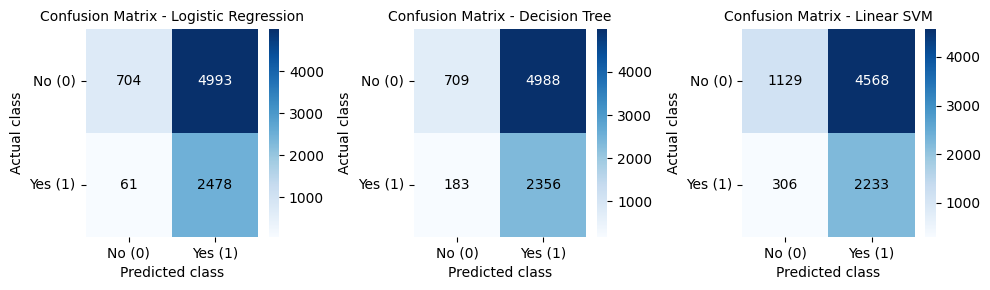

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Store test-set confusion matrices for the classical models
conf_matrices = {
    "Logistic Regression": confusion_matrix(y_test, lr_test_pred, labels=[0, 1]),
    "Decision Tree": confusion_matrix(y_test, dt_test_pred, labels=[0, 1]),
    "Linear SVM": confusion_matrix(y_test, svm_test_pred, labels=[0, 1])
}

# Visualize the confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for ax, (name, matrix) in zip(axes, conf_matrices.items()):
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )
    
     # Make annotation colours readable
    threshold = matrix.max() / 2
    for text, value in zip(ax.texts, matrix.flatten()):
        text.set_color("white" if value > threshold else "black")
        
    ax.set_title(f"Confusion Matrix - {name}", fontsize=10)
    ax.set_xticklabels(["No (0)", "Yes (1)"])
    ax.set_yticklabels(["No (0)", "Yes (1)"], rotation=0)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()

### RQ2

In [60]:
# Define the sets for RQ2
rq2_sets = {
    "Set A": {
        "X_train": X_train_without,
        "X_test": X_test_without,
        "preprocessor": preprocessor_without
    },
    "Set B": {
        "X_train": X_train_with,
        "X_test": X_test_with,
        "preprocessor": preprocessor_with
    }
}

### RQ2: Logistic Regression

Candidate 1/6, fold 1 complete
Candidate 1/6, fold 2 complete
Candidate 1/6, fold 3 complete
Candidate 1/6, fold 4 complete
Candidate 1/6, fold 5 complete
Candidate 2/6, fold 1 complete
Candidate 2/6, fold 2 complete
Candidate 2/6, fold 3 complete
Candidate 2/6, fold 4 complete
Candidate 2/6, fold 5 complete
Candidate 3/6, fold 1 complete
Candidate 3/6, fold 2 complete
Candidate 3/6, fold 3 complete
Candidate 3/6, fold 4 complete
Candidate 3/6, fold 5 complete
Candidate 4/6, fold 1 complete
Candidate 4/6, fold 2 complete
Candidate 4/6, fold 3 complete
Candidate 4/6, fold 4 complete
Candidate 4/6, fold 5 complete
Candidate 5/6, fold 1 complete
Candidate 5/6, fold 2 complete
Candidate 5/6, fold 3 complete
Candidate 5/6, fold 4 complete
Candidate 5/6, fold 5 complete
Candidate 6/6, fold 1 complete
Candidate 6/6, fold 2 complete
Candidate 6/6, fold 3 complete
Candidate 6/6, fold 4 complete
Candidate 6/6, fold 5 complete
Logistic Regression - Set A


,Candidate,Threshold,Default CV F1,CV F1,CV F1 SD,CV Precision,CV Recall,CV ROC-AUC,CV predicted yes rate
0,0.0,0.05,0.0,0.0811,0.0914,0.0549,0.1816,0.5224,0.1628
1,1.0,0.05,0.0,0.0996,0.0784,0.0770,0.2286,0.5218,0.2125
2,2.0,0.05,0.0,0.1088,0.0742,0.0747,0.2567,0.5222,0.2362
3,3.0,0.05,0.0,0.1097,0.0716,0.0745,0.2597,0.5218,0.2408
4,4.0,0.05,0.0,0.1098,0.0718,0.0745,0.2613,0.5217,0.2416
5,5.0,0.05,0.0,0.1104,0.0714,0.0749,0.2619,0.5217,0.2418


Selected parameters: {'C': 1000}
Selected threshold: 0.05
Mean validation F1: 0.1104


,Candidate,Fold,Threshold,Training F1,Accuracy,Precision,Recall,F1,ROC-AUC,Predicted yes rate,Convergence warnings
5,5,1,0.05,0.0669,0.9047,0.0387,0.0610,0.0474,0.5120,0.0612,0
11,5,2,0.05,0.0689,0.8814,0.0606,0.0663,0.0633,0.5067,0.0661,0
17,5,3,0.05,0.0944,0.7849,0.0588,0.1754,0.0880,0.4887,0.1767,0
23,5,4,0.05,0.1000,0.6233,0.0606,0.4080,0.1055,0.5341,0.3667,0
29,5,5,0.05,0.1019,0.4894,0.1560,0.5987,0.2475,0.5672,0.5383,0


Search convergence warnings: 0
Refit convergence warnings: []
Candidate 1/6, fold 1 complete
Candidate 1/6, fold 2 complete
Candidate 1/6, fold 3 complete
Candidate 1/6, fold 4 complete
Candidate 1/6, fold 5 complete
Candidate 2/6, fold 1 complete
Candidate 2/6, fold 2 complete
Candidate 2/6, fold 3 complete
Candidate 2/6, fold 4 complete
Candidate 2/6, fold 5 complete
Candidate 3/6, fold 1 complete
Candidate 3/6, fold 2 complete
Candidate 3/6, fold 3 complete
Candidate 3/6, fold 4 complete
Candidate 3/6, fold 5 complete
Candidate 4/6, fold 1 complete
Candidate 4/6, fold 2 complete
Candidate 4/6, fold 3 complete
Candidate 4/6, fold 4 complete
Candidate 4/6, fold 5 complete
Candidate 5/6, fold 1 complete
Candidate 5/6, fold 2 complete
Candidate 5/6, fold 3 complete
Candidate 5/6, fold 4 complete
Candidate 5/6, fold 5 complete
Candidate 6/6, fold 1 complete
Candidate 6/6, fold 2 complete
Candidate 6/6, fold 3 complete
Candidate 6/6, fold 4 complete
Candidate 6/6, fold 5 complete
Logistic

,Candidate,Threshold,Default CV F1,CV F1,CV F1 SD,CV Precision,CV Recall,CV ROC-AUC,CV predicted yes rate
0,0.0,0.05,0.000,0.0889,0.1057,0.0618,0.1800,0.5362,0.1436
1,1.0,0.05,0.001,0.1069,0.0915,0.0831,0.2244,0.5333,0.1902
2,2.0,0.05,0.000,0.1140,0.0873,0.0799,0.2578,0.5278,0.2297
3,3.0,0.05,0.000,0.1155,0.0861,0.0800,0.2612,0.5284,0.2323
4,4.0,0.05,0.000,0.1148,0.0866,0.0796,0.2603,0.5284,0.2320
5,5.0,0.05,0.000,0.1149,0.0866,0.0796,0.2603,0.5284,0.2319


Selected parameters: {'C': 10}
Selected threshold: 0.05
Mean validation F1: 0.1155


,Candidate,Fold,Threshold,Training F1,Accuracy,Precision,Recall,F1,ROC-AUC,Predicted yes rate,Convergence warnings
5,3,1,0.05,0.0691,0.9042,0.0383,0.0610,0.0471,0.5119,0.0617,0
11,3,2,0.05,0.0715,0.8825,0.0592,0.0633,0.0611,0.5080,0.0647,0
17,3,3,0.05,0.0949,0.7898,0.0595,0.1723,0.0885,0.4905,0.1714,0
23,3,4,0.05,0.1009,0.5541,0.0543,0.4381,0.0967,0.5034,0.4392,0
29,3,5,0.05,0.1020,0.5956,0.1888,0.5714,0.2839,0.6281,0.4244,0


Search convergence warnings: 0
Refit convergence warnings: []


,Model,Feature Set,Best Parameter,Threshold,Mean CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Set A,{'C': 1000},0.05,0.1104,0.3533,0.3176,0.9559,0.4768,0.5773
1,Logistic Regression,Set B,{'C': 10},0.05,0.1155,0.3680,0.3230,0.9579,0.4831,0.6850


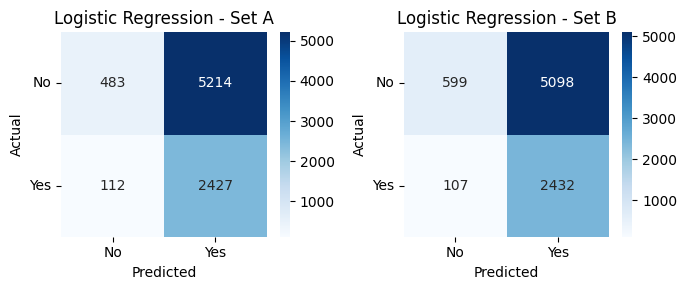

In [61]:
lr_rq2_tuning, lr_rq2_best = {}, {}
lr_rq2_models, lr_rq2_predictions = {}, {}
lr_rq2_results, lr_conf_matrices = [], {}

for set_name, data in rq2_sets.items():
    search = tune_model(data["preprocessor"], lr_model, lr_candidates,
                        data["X_train"], probability_thresholds)
    print("Logistic Regression -", set_name)
    show_search(search)
    lr_rq2_tuning[set_name] = search["tuning"]
    lr_rq2_best[set_name] = {**search["settings"], "Threshold": search["Threshold"],
                                 "Mean CV F1": search["CV F1"]}
    pipeline, messages = fit_pipeline(data["preprocessor"], lr_model,
                                      search["settings"], data["X_train"], y_train)
    prediction = predict_at_threshold(pipeline, data["X_test"], search["Threshold"])
    lr_rq2_models[set_name] = pipeline
    lr_rq2_predictions[set_name] = prediction
    lr_conf_matrices[set_name] = confusion_matrix(y_test, prediction, labels=[0, 1])
    lr_rq2_results.append({
        "Model": "Logistic Regression", "Feature Set": set_name,
        "Best Parameter": str(search["settings"]), "Threshold": search["Threshold"],
        "Mean CV F1": search["CV F1"],
        **evaluate_model(y_test, prediction, positive_score(pipeline, data["X_test"]))
    })
    print("Refit convergence warnings:", messages)

lr_rq2_results_df = pd.DataFrame(lr_rq2_results)
display(lr_rq2_results_df.round(4))
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, (set_name, matrix) in zip(axes, lr_conf_matrices.items()):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set(title=f"Logistic Regression - {set_name}", xlabel="Predicted", ylabel="Actual")
    ax.set_xticklabels(["No", "Yes"])
    ax.set_yticklabels(["No", "Yes"], rotation=0)
plt.tight_layout()
plt.show()


### RQ2: Decision Tree

Candidate 1/18, fold 1 complete
Candidate 1/18, fold 2 complete
Candidate 1/18, fold 3 complete
Candidate 1/18, fold 4 complete
Candidate 1/18, fold 5 complete
Candidate 2/18, fold 1 complete
Candidate 2/18, fold 2 complete
Candidate 2/18, fold 3 complete
Candidate 2/18, fold 4 complete
Candidate 2/18, fold 5 complete
Candidate 3/18, fold 1 complete
Candidate 3/18, fold 2 complete
Candidate 3/18, fold 3 complete
Candidate 3/18, fold 4 complete
Candidate 3/18, fold 5 complete
Candidate 4/18, fold 1 complete
Candidate 4/18, fold 2 complete
Candidate 4/18, fold 3 complete
Candidate 4/18, fold 4 complete
Candidate 4/18, fold 5 complete
Candidate 5/18, fold 1 complete
Candidate 5/18, fold 2 complete
Candidate 5/18, fold 3 complete
Candidate 5/18, fold 4 complete
Candidate 5/18, fold 5 complete
Candidate 6/18, fold 1 complete
Candidate 6/18, fold 2 complete
Candidate 6/18, fold 3 complete
Candidate 6/18, fold 4 complete
Candidate 6/18, fold 5 complete
Candidate 7/18, fold 1 complete
Candidat

,Candidate,Threshold,Default CV F1,CV F1,CV F1 SD,CV Precision,CV Recall,CV ROC-AUC,CV predicted yes rate
0,0.0,0.05,0.0000,0.0865,0.0913,0.0567,0.1884,0.5112,0.1693
1,1.0,0.05,0.0000,0.0865,0.0913,0.0567,0.1884,0.5112,0.1693
2,2.0,0.05,0.0000,0.0865,0.0913,0.0567,0.1884,0.5112,0.1693
3,3.0,0.05,0.0000,0.1118,0.0641,0.0743,0.2471,0.5145,0.2334
4,4.0,0.05,0.0000,0.0994,0.0742,0.0770,0.2355,0.5166,0.2197
5,5.0,0.05,0.0000,0.1039,0.0711,0.0786,0.2500,0.5195,0.2303
6,6.0,0.05,0.0000,0.1230,0.0593,0.0780,0.3259,0.5167,0.2966
7,7.0,0.05,0.0000,0.1114,0.0647,0.0722,0.2712,0.5058,0.2711
8,8.0,0.05,0.0053,0.1090,0.0666,0.0707,0.2699,0.5047,0.2722
9,9.0,0.05,0.0000,0.1224,0.0607,0.0758,0.3575,0.5108,0.3387


Selected parameters: {'max_depth': 10, 'min_samples_leaf': 100}
Selected threshold: 0.05
Mean validation F1: 0.123


,Candidate,Fold,Threshold,Training F1,Accuracy,Precision,Recall,F1,ROC-AUC,Predicted yes rate,Convergence warnings
5,6,1,0.05,0.1220,0.8208,0.0416,0.1643,0.0664,0.5071,0.1532,0
11,6,2,0.05,0.1144,0.7545,0.0673,0.2380,0.1049,0.5144,0.2138,0
17,6,3,0.05,0.1258,0.7071,0.0597,0.2677,0.0976,0.4830,0.2654,0
23,6,4,0.05,0.1216,0.5457,0.0605,0.5050,0.1080,0.5223,0.4548,0
29,6,5,0.05,0.1284,0.5916,0.1611,0.4545,0.2379,0.5566,0.3956,0


Search convergence warnings: 0
Refit convergence warnings: []
Candidate 1/18, fold 1 complete
Candidate 1/18, fold 2 complete
Candidate 1/18, fold 3 complete
Candidate 1/18, fold 4 complete
Candidate 1/18, fold 5 complete
Candidate 2/18, fold 1 complete
Candidate 2/18, fold 2 complete
Candidate 2/18, fold 3 complete
Candidate 2/18, fold 4 complete
Candidate 2/18, fold 5 complete
Candidate 3/18, fold 1 complete
Candidate 3/18, fold 2 complete
Candidate 3/18, fold 3 complete
Candidate 3/18, fold 4 complete
Candidate 3/18, fold 5 complete
Candidate 4/18, fold 1 complete
Candidate 4/18, fold 2 complete
Candidate 4/18, fold 3 complete
Candidate 4/18, fold 4 complete
Candidate 4/18, fold 5 complete
Candidate 5/18, fold 1 complete
Candidate 5/18, fold 2 complete
Candidate 5/18, fold 3 complete
Candidate 5/18, fold 4 complete
Candidate 5/18, fold 5 complete
Candidate 6/18, fold 1 complete
Candidate 6/18, fold 2 complete
Candidate 6/18, fold 3 complete
Candidate 6/18, fold 4 complete
Candidate 

,Candidate,Threshold,Default CV F1,CV F1,CV F1 SD,CV Precision,CV Recall,CV ROC-AUC,CV predicted yes rate
0,0.0,0.05,0.0000,0.0865,0.0913,0.0567,0.1884,0.5112,0.1693
1,1.0,0.05,0.0000,0.0865,0.0913,0.0567,0.1884,0.5112,0.1693
2,2.0,0.05,0.0000,0.0865,0.0913,0.0567,0.1884,0.5112,0.1693
3,3.0,0.05,0.0000,0.1231,0.0854,0.0800,0.2934,0.5221,0.2553
4,4.0,0.05,0.0000,0.1091,0.0923,0.0815,0.2862,0.5222,0.2479
5,5.0,0.05,0.0031,0.1134,0.0890,0.0830,0.3006,0.5257,0.2584
6,6.0,0.05,0.0000,0.1249,0.0631,0.0797,0.3272,0.5193,0.2938
7,7.0,0.05,0.0000,0.1147,0.0696,0.0746,0.2758,0.5117,0.2687
8,8.0,0.05,0.0114,0.1092,0.0667,0.0720,0.2579,0.5142,0.2581
9,9.0,0.05,0.0000,0.1222,0.0603,0.0767,0.3484,0.5142,0.3285


Selected parameters: {'max_depth': 10, 'min_samples_leaf': 100}
Selected threshold: 0.05
Mean validation F1: 0.1249


,Candidate,Fold,Threshold,Training F1,Accuracy,Precision,Recall,F1,ROC-AUC,Predicted yes rate,Convergence warnings
5,6,1,0.05,0.1220,0.8208,0.0416,0.1643,0.0664,0.5071,0.1532,0
11,6,2,0.05,0.1144,0.7545,0.0673,0.2380,0.1049,0.5144,0.2138,0
17,6,3,0.05,0.1258,0.7071,0.0597,0.2677,0.0976,0.4833,0.2654,0
23,6,4,0.05,0.1216,0.5459,0.0605,0.5050,0.1081,0.5229,0.4546,0
29,6,5,0.05,0.1253,0.6069,0.1692,0.4610,0.2476,0.5687,0.3821,0


Search convergence warnings: 0
Refit convergence warnings: []


,Model,Feature Set,Best Parameter,Threshold,Mean CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
0,Decision Tree,Set A,"{'max_depth': 10, 'min_samples_leaf': 100}",0.05,0.1230,0.3919,0.3221,0.8807,0.4717,0.5760
1,Decision Tree,Set B,"{'max_depth': 10, 'min_samples_leaf': 100}",0.05,0.1249,0.4161,0.3324,0.8866,0.4835,0.6621


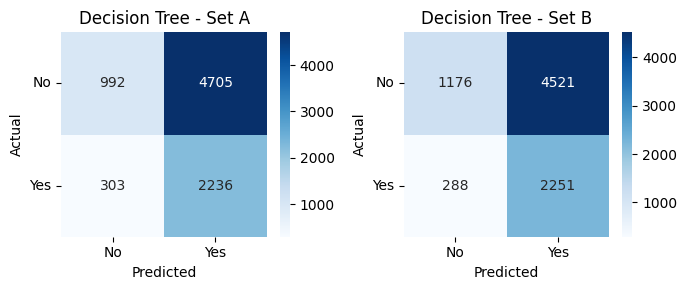

In [62]:
dt_rq2_tuning, dt_rq2_best = {}, {}
dt_rq2_models, dt_rq2_predictions = {}, {}
dt_rq2_results, dt_conf_matrices = [], {}

for set_name, data in rq2_sets.items():
    search = tune_model(data["preprocessor"], dt_model, dt_candidates,
                        data["X_train"], probability_thresholds)
    print("Decision Tree -", set_name)
    show_search(search)
    dt_rq2_tuning[set_name] = search["tuning"]
    dt_rq2_best[set_name] = {**search["settings"], "Threshold": search["Threshold"],
                                 "Mean CV F1": search["CV F1"]}
    pipeline, messages = fit_pipeline(data["preprocessor"], dt_model,
                                      search["settings"], data["X_train"], y_train)
    prediction = predict_at_threshold(pipeline, data["X_test"], search["Threshold"])
    dt_rq2_models[set_name] = pipeline
    dt_rq2_predictions[set_name] = prediction
    dt_conf_matrices[set_name] = confusion_matrix(y_test, prediction, labels=[0, 1])
    dt_rq2_results.append({
        "Model": "Decision Tree", "Feature Set": set_name,
        "Best Parameter": str(search["settings"]), "Threshold": search["Threshold"],
        "Mean CV F1": search["CV F1"],
        **evaluate_model(y_test, prediction, positive_score(pipeline, data["X_test"]))
    })
    print("Refit convergence warnings:", messages)

dt_rq2_results_df = pd.DataFrame(dt_rq2_results)
display(dt_rq2_results_df.round(4))
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, (set_name, matrix) in zip(axes, dt_conf_matrices.items()):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set(title=f"Decision Tree - {set_name}", xlabel="Predicted", ylabel="Actual")
    ax.set_xticklabels(["No", "Yes"])
    ax.set_yticklabels(["No", "Yes"], rotation=0)
plt.tight_layout()
plt.show()


### RQ2: Linear SVM

Candidate 1/3, fold 1 complete
Candidate 1/3, fold 2 complete
Candidate 1/3, fold 3 complete
Candidate 1/3, fold 4 complete
Candidate 1/3, fold 5 complete
Candidate 2/3, fold 1 complete
Candidate 2/3, fold 2 complete
Candidate 2/3, fold 3 complete
Candidate 2/3, fold 4 complete
Candidate 2/3, fold 5 complete
Candidate 3/3, fold 1 complete
Candidate 3/3, fold 2 complete
Candidate 3/3, fold 3 complete
Candidate 3/3, fold 4 complete
Candidate 3/3, fold 5 complete
Linear SVM - Set A


,Candidate,Threshold,Default CV F1,CV F1,CV F1 SD,CV Precision,CV Recall,CV ROC-AUC,CV predicted yes rate
0,0.0,-1.01,0.0,0.130,0.0597,0.0706,1.0000,0.4946,1.000
1,1.0,-1.01,0.0,0.130,0.0597,0.0706,1.0000,0.4796,1.000
2,2.0,-1.00,0.0,0.132,0.0647,0.0757,0.6529,0.5245,0.626


Selected parameters: {'C': 1}
Selected threshold: -1.0
Mean validation F1: 0.132


,Candidate,Fold,Threshold,Training F1,Accuracy,Precision,Recall,F1,ROC-AUC,Predicted yes rate,Convergence warnings
7,2,1,-1.0,0.0533,0.4392,0.0389,0.5681,0.0729,0.5184,0.5661,0
16,2,2,-1.0,0.0691,0.4659,0.0652,0.5873,0.1174,0.5140,0.5446,0
25,2,3,-1.0,0.0814,0.3401,0.0610,0.7046,0.1122,0.5201,0.6842,0
34,2,4,-1.0,0.0867,0.2780,0.0536,0.7358,0.0999,0.5013,0.7477,0
43,2,5,-1.0,0.0919,0.4599,0.1597,0.6688,0.2578,0.5689,0.5874,0


Search convergence warnings: 0
Refit convergence warnings: []
Candidate 1/3, fold 1 complete
Candidate 1/3, fold 2 complete
Candidate 1/3, fold 3 complete
Candidate 1/3, fold 4 complete
Candidate 1/3, fold 5 complete
Candidate 2/3, fold 1 complete
Candidate 2/3, fold 2 complete
Candidate 2/3, fold 3 complete
Candidate 2/3, fold 4 complete
Candidate 2/3, fold 5 complete
Candidate 3/3, fold 1 complete
Candidate 3/3, fold 2 complete
Candidate 3/3, fold 3 complete
Candidate 3/3, fold 4 complete
Candidate 3/3, fold 5 complete
Linear SVM - Set B


,Candidate,Threshold,Default CV F1,CV F1,CV F1 SD,CV Precision,CV Recall,CV ROC-AUC,CV predicted yes rate
0,0.0,-1.01,0.0,0.13,0.0597,0.0706,1.0,0.4886,1.0
1,1.0,-1.01,0.0,0.13,0.0597,0.0706,1.0,0.4736,1.0
2,2.0,-1.01,0.0,0.13,0.0597,0.0706,1.0,0.5002,1.0


Selected parameters: {'C': 0.01}
Selected threshold: -1.01
Mean validation F1: 0.13


,Candidate,Fold,Threshold,Training F1,Accuracy,Precision,Recall,F1,ROC-AUC,Predicted yes rate,Convergence warnings
8,0,1,-1.01,0.0570,0.0388,0.0388,1.0,0.0747,0.4735,1.0,0
17,0,2,-1.01,0.0659,0.0605,0.0605,1.0,0.1141,0.4914,1.0,0
26,0,3,-1.01,0.0822,0.0592,0.0592,1.0,0.1118,0.5180,1.0,0
35,0,4,-1.01,0.0897,0.0545,0.0545,1.0,0.1033,0.5169,1.0,0
44,0,5,-1.01,0.0924,0.1403,0.1403,1.0,0.2460,0.4432,1.0,0


Search convergence warnings: 0
Refit convergence warnings: []


,Model,Feature Set,Best Parameter,Threshold,Mean CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
0,Linear SVM,Set A,{'C': 1},-1.00,0.132,0.3865,0.3014,0.7511,0.4301,0.5115
1,Linear SVM,Set B,{'C': 0.01},-1.01,0.130,0.3083,0.3083,1.0000,0.4713,0.5959


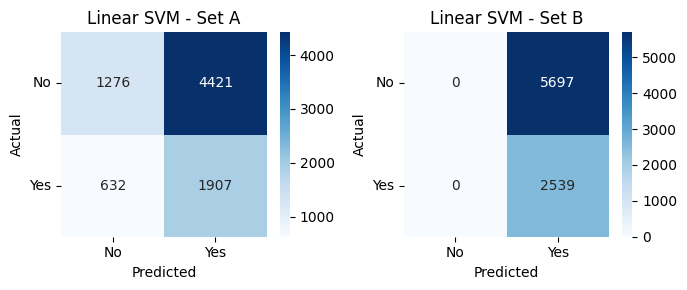

In [63]:
svm_rq2_tuning, svm_rq2_best = {}, {}
svm_rq2_models, svm_rq2_predictions = {}, {}
svm_rq2_results, svm_conf_matrices = [], {}

for set_name, data in rq2_sets.items():
    search = tune_model(data["preprocessor"], svm_model, svm_candidates,
                        data["X_train"], margin_thresholds)
    print("Linear SVM -", set_name)
    show_search(search)
    svm_rq2_tuning[set_name] = search["tuning"]
    svm_rq2_best[set_name] = {**search["settings"], "Threshold": search["Threshold"],
                                 "Mean CV F1": search["CV F1"]}
    pipeline, messages = fit_pipeline(data["preprocessor"], svm_model,
                                      search["settings"], data["X_train"], y_train)
    prediction = predict_at_threshold(pipeline, data["X_test"], search["Threshold"])
    svm_rq2_models[set_name] = pipeline
    svm_rq2_predictions[set_name] = prediction
    svm_conf_matrices[set_name] = confusion_matrix(y_test, prediction, labels=[0, 1])
    svm_rq2_results.append({
        "Model": "Linear SVM", "Feature Set": set_name,
        "Best Parameter": str(search["settings"]), "Threshold": search["Threshold"],
        "Mean CV F1": search["CV F1"],
        **evaluate_model(y_test, prediction, positive_score(pipeline, data["X_test"]))
    })
    print("Refit convergence warnings:", messages)

svm_rq2_results_df = pd.DataFrame(svm_rq2_results)
display(svm_rq2_results_df.round(4))
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, (set_name, matrix) in zip(axes, svm_conf_matrices.items()):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set(title=f"Linear SVM - {set_name}", xlabel="Predicted", ylabel="Actual")
    ax.set_xticklabels(["No", "Yes"])
    ax.set_yticklabels(["No", "Yes"], rotation=0)
plt.tight_layout()
plt.show()


### RQ2: Classical-only Summary Tables

In [64]:
# RQ2 unified results table: Set A vs Set B

print("RQ2 Test Performance Comparison: Set A vs Set B")
rq2_all_results = pd.concat(
    [
        lr_rq2_results_df,
        dt_rq2_results_df,
        svm_rq2_results_df
    ],
    ignore_index=True
)

rq2_table_ab = rq2_all_results[
    [
        "Model",
        "Feature Set",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
].copy()

display(
    rq2_table_ab.round(4)
)




print("RQ2 Performance Change between Set A and Set B (B - A)")
# RQ2 performance change table: Set B - Set A

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

delta_rows = []

for model_name in rq2_all_results["Model"].unique():

    model_results = rq2_all_results[
        rq2_all_results["Model"] == model_name
    ].set_index("Feature Set")

    delta_rows.append({
        "Model": model_name,
        "Δ Accuracy": (
            model_results.loc["Set B", "Accuracy"]
            - model_results.loc["Set A", "Accuracy"]
        ),
        "Δ Precision": (
            model_results.loc["Set B", "Precision"]
            - model_results.loc["Set A", "Precision"]
        ),
        "Δ Recall": (
            model_results.loc["Set B", "Recall"]
            - model_results.loc["Set A", "Recall"]
        ),
        "Δ F1": (
            model_results.loc["Set B", "F1"]
            - model_results.loc["Set A", "F1"]
        ),
        "Δ ROC-AUC": (
            model_results.loc["Set B", "ROC-AUC"]
            - model_results.loc["Set A", "ROC-AUC"]
        )
    })

rq2_delta_table = pd.DataFrame(delta_rows)

display(
    rq2_delta_table.round(4)
)

RQ2 Test Performance Comparison: Set A vs Set B


,Model,Feature Set,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Set A,0.3533,0.3176,0.9559,0.4768,0.5773
1,Logistic Regression,Set B,0.3680,0.3230,0.9579,0.4831,0.6850
2,Decision Tree,Set A,0.3919,0.3221,0.8807,0.4717,0.5760
3,Decision Tree,Set B,0.4161,0.3324,0.8866,0.4835,0.6621
4,Linear SVM,Set A,0.3865,0.3014,0.7511,0.4301,0.5115
5,Linear SVM,Set B,0.3083,0.3083,1.0000,0.4713,0.5959


RQ2 Performance Change between Set A and Set B (B - A)


,Model,Δ Accuracy,Δ Precision,Δ Recall,Δ F1,Δ ROC-AUC
0,Logistic Regression,0.0147,0.0053,0.0020,0.0062,0.1077
1,Decision Tree,0.0242,0.0103,0.0059,0.0118,0.0861
2,Linear SVM,-0.0782,0.0069,0.2489,0.0411,0.0845


## 13. Classical-model RQ2 Results

The following tables summarise parameter selection and test performance for
Logistic Regression, Decision Tree and Linear SVM on Set A and Set B.
The MLP comparison is presented in Section 16.2.


In [65]:
# Reuse the feature-set definitions already used in the classical RQ2 experiments.
assert set(rq2_sets) == {"Set A", "Set B"}
for data in rq2_sets.values():
    assert data["X_train"].index.equals(y_train.index)
    assert data["X_test"].index.equals(y_test.index)

### 13.1 Logistic Regression

In [66]:
# Reuse previously computed results; no additional model fitting.
for set_name in rq2_sets:
    print("Logistic Regression -", set_name)
    display(lr_rq2_tuning[set_name].round(4))
    print("Best C:", lr_rq2_best[set_name]["C"])
    print("Best CV F1:", round(lr_rq2_best[set_name]["Mean CV F1"], 4))
display(lr_rq2_results_df.round(4))

Logistic Regression - Set A


,Candidate,C,Threshold,Training F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 SD,CV ROC-AUC SD,CV predicted yes rate,Convergence warnings,Default CV F1
0,0.0,0.01,0.05,0.0556,0.8056,0.0549,0.1816,0.0811,0.5224,0.0914,0.0264,0.1628,0.0,0.0
1,1.0,0.10,0.05,0.0769,0.7621,0.0770,0.2286,0.0996,0.5218,0.0784,0.0266,0.2125,0.0,0.0
2,2.0,1.00,0.05,0.0870,0.7420,0.0747,0.2567,0.1088,0.5222,0.0742,0.0279,0.2362,0.0,0.0
3,3.0,10.00,0.05,0.0868,0.7375,0.0745,0.2597,0.1097,0.5218,0.0716,0.0270,0.2408,0.0,0.0
4,4.0,100.00,0.05,0.0865,0.7368,0.0745,0.2613,0.1098,0.5217,0.0718,0.0270,0.2416,0.0,0.0
5,5.0,1000.00,0.05,0.0864,0.7368,0.0749,0.2619,0.1104,0.5217,0.0714,0.0270,0.2418,0.0,0.0


Best C: 1000
Best CV F1: 0.1104
Logistic Regression - Set B


,Candidate,C,Threshold,Training F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 SD,CV ROC-AUC SD,CV predicted yes rate,Convergence warnings,Default CV F1
0,0.0,0.01,0.05,0.0561,0.8244,0.0618,0.1800,0.0889,0.5362,0.1057,0.0524,0.1436,0.0,0.000
1,1.0,0.10,0.05,0.0777,0.7832,0.0831,0.2244,0.1069,0.5333,0.0915,0.0482,0.1902,0.0,0.001
2,2.0,1.00,0.05,0.0868,0.7475,0.0799,0.2578,0.1140,0.5278,0.0873,0.0509,0.2297,0.0,0.000
3,3.0,10.00,0.05,0.0877,0.7452,0.0800,0.2612,0.1155,0.5284,0.0861,0.0504,0.2323,0.0,0.000
4,4.0,100.00,0.05,0.0878,0.7455,0.0796,0.2603,0.1148,0.5284,0.0866,0.0504,0.2320,0.0,0.000
5,5.0,1000.00,0.05,0.0878,0.7455,0.0796,0.2603,0.1149,0.5284,0.0866,0.0504,0.2319,0.0,0.000


Best C: 10
Best CV F1: 0.1155


,Model,Feature Set,Best Parameter,Threshold,Mean CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Set A,{'C': 1000},0.05,0.1104,0.3533,0.3176,0.9559,0.4768,0.5773
1,Logistic Regression,Set B,{'C': 10},0.05,0.1155,0.3680,0.3230,0.9579,0.4831,0.6850


### 13.2 Decision Tree

In [67]:
# Reuse previously computed results; no additional model fitting.
for set_name in rq2_sets:
    print("Decision Tree -", set_name)
    display(dt_rq2_tuning[set_name].round(4))
    print("Best max_depth:", dt_rq2_best[set_name]["max_depth"])
    print("Best CV F1:", round(dt_rq2_best[set_name]["Mean CV F1"], 4))
display(dt_rq2_results_df.round(4))

Decision Tree - Set A


,Candidate,max_depth,min_samples_leaf,Threshold,Training F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 SD,CV ROC-AUC SD,CV predicted yes rate,Convergence warnings,Default CV F1
0,0.0,1.0,100.0,0.05,0.0551,0.7977,0.0567,0.1884,0.0865,0.5112,0.0913,0.0183,0.1693,0.0,0.0000
1,1.0,1.0,20.0,0.05,0.0551,0.7977,0.0567,0.1884,0.0865,0.5112,0.0913,0.0183,0.1693,0.0,0.0000
2,2.0,1.0,1.0,0.05,0.0551,0.7977,0.0567,0.1884,0.0865,0.5112,0.0913,0.0183,0.1693,0.0,0.0000
3,3.0,5.0,100.0,0.05,0.1036,0.7402,0.0743,0.2471,0.1118,0.5145,0.0641,0.0209,0.2334,0.0,0.0000
4,4.0,5.0,20.0,0.05,0.0944,0.7536,0.0770,0.2355,0.0994,0.5166,0.0742,0.0182,0.2197,0.0,0.0000
5,5.0,5.0,1.0,0.05,0.0994,0.7451,0.0786,0.2500,0.1039,0.5195,0.0711,0.0147,0.2303,0.0,0.0000
6,6.0,10.0,100.0,0.05,0.1224,0.6839,0.0780,0.3259,0.1230,0.5167,0.0593,0.0239,0.2966,0.0,0.0000
7,7.0,10.0,20.0,0.05,0.1398,0.7047,0.0722,0.2712,0.1114,0.5058,0.0647,0.0247,0.2711,0.0,0.0000
8,8.0,10.0,1.0,0.05,0.1567,0.7052,0.0707,0.2699,0.1090,0.5047,0.0666,0.0155,0.2722,0.0,0.0053
9,9.0,15.0,100.0,0.05,0.1266,0.6468,0.0758,0.3575,0.1224,0.5108,0.0607,0.0166,0.3387,0.0,0.0000


Best max_depth: 10
Best CV F1: 0.123
Decision Tree - Set B


,Candidate,max_depth,min_samples_leaf,Threshold,Training F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 SD,CV ROC-AUC SD,CV predicted yes rate,Convergence warnings,Default CV F1
0,0.0,1.0,100.0,0.05,0.0551,0.7977,0.0567,0.1884,0.0865,0.5112,0.0913,0.0183,0.1693,0.0,0.0000
1,1.0,1.0,20.0,0.05,0.0551,0.7977,0.0567,0.1884,0.0865,0.5112,0.0913,0.0183,0.1693,0.0,0.0000
2,2.0,1.0,1.0,0.05,0.0551,0.7977,0.0567,0.1884,0.0865,0.5112,0.0913,0.0183,0.1693,0.0,0.0000
3,3.0,5.0,100.0,0.05,0.1029,0.7313,0.0800,0.2934,0.1231,0.5221,0.0854,0.0353,0.2553,0.0,0.0000
4,4.0,5.0,20.0,0.05,0.0939,0.7397,0.0815,0.2862,0.1091,0.5222,0.0923,0.0304,0.2479,0.0,0.0000
5,5.0,5.0,1.0,0.05,0.0989,0.7313,0.0830,0.3006,0.1134,0.5257,0.0890,0.0254,0.2584,0.0,0.0031
6,6.0,10.0,100.0,0.05,0.1218,0.6870,0.0797,0.3272,0.1249,0.5193,0.0631,0.0280,0.2938,0.0,0.0000
7,7.0,10.0,20.0,0.05,0.1389,0.7082,0.0746,0.2758,0.1147,0.5117,0.0696,0.0316,0.2687,0.0,0.0000
8,8.0,10.0,1.0,0.05,0.1562,0.7160,0.0720,0.2579,0.1092,0.5142,0.0667,0.0304,0.2581,0.0,0.0114
9,9.0,15.0,100.0,0.05,0.1266,0.6545,0.0767,0.3484,0.1222,0.5142,0.0603,0.0230,0.3285,0.0,0.0000


Best max_depth: 10
Best CV F1: 0.1249


,Model,Feature Set,Best Parameter,Threshold,Mean CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
0,Decision Tree,Set A,"{'max_depth': 10, 'min_samples_leaf': 100}",0.05,0.1230,0.3919,0.3221,0.8807,0.4717,0.5760
1,Decision Tree,Set B,"{'max_depth': 10, 'min_samples_leaf': 100}",0.05,0.1249,0.4161,0.3324,0.8866,0.4835,0.6621


### 13.3 Linear SVM

In [68]:
# Reuse previously computed results; no additional model fitting.
for set_name in rq2_sets:
    print("Linear SVM -", set_name)
    display(svm_rq2_tuning[set_name].round(4))
    print("Best C:", svm_rq2_best[set_name]["C"])
    print("Best CV F1:", round(svm_rq2_best[set_name]["Mean CV F1"], 4))
display(svm_rq2_results_df.round(4))

Linear SVM - Set A


,Candidate,C,Threshold,Training F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 SD,CV ROC-AUC SD,CV predicted yes rate,Convergence warnings,Default CV F1
0,0.0,0.01,-1.01,0.0774,0.0706,0.0706,1.0000,0.130,0.4946,0.0597,0.0129,1.000,0.0,0.0
1,1.0,0.10,-1.01,0.0774,0.0706,0.0706,1.0000,0.130,0.4796,0.0597,0.0379,1.000,0.0,0.0
2,2.0,1.00,-1.00,0.0765,0.3966,0.0757,0.6529,0.132,0.5245,0.0647,0.0232,0.626,0.0,0.0


Best C: 1
Best CV F1: 0.132
Linear SVM - Set B


,Candidate,C,Threshold,Training F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 SD,CV ROC-AUC SD,CV predicted yes rate,Convergence warnings,Default CV F1
0,0.0,0.01,-1.01,0.0774,0.0706,0.0706,1.0,0.13,0.4886,0.0597,0.0281,1.0,0.0,0.0
1,1.0,0.10,-1.01,0.0774,0.0706,0.0706,1.0,0.13,0.4736,0.0597,0.0207,1.0,0.0,0.0
2,2.0,1.00,-1.01,0.0774,0.0706,0.0706,1.0,0.13,0.5002,0.0597,0.0244,1.0,0.0,0.0


Best C: 0.01
Best CV F1: 0.13


,Model,Feature Set,Best Parameter,Threshold,Mean CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
0,Linear SVM,Set A,{'C': 1},-1.00,0.132,0.3865,0.3014,0.7511,0.4301,0.5115
1,Linear SVM,Set B,{'C': 0.01},-1.01,0.130,0.3083,0.3083,1.0000,0.4713,0.5959


### 13.5 Detailed Classical-model RQ2 Results

This table summarises held-out test results using accuracy, precision, recall, F1 and ROC-AUC.
Classical models are tuned separately for each feature set. The summary including the final gradient-descent MLP appears in Section 16.2.


In [69]:
rq2_results = pd.concat([
    lr_rq2_results_df.assign(**{"Tuning Strategy": "Separate search per feature set"}),
    dt_rq2_results_df.assign(**{"Tuning Strategy": "Separate search per feature set"}),
    svm_rq2_results_df.assign(**{"Tuning Strategy": "Separate search per feature set"})
], ignore_index=True)[[
    "Model", "Feature Set", "Tuning Strategy", "Mean CV F1",
    "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"
]]
display(rq2_results.round(4))

,Model,Feature Set,Tuning Strategy,Mean CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Set A,Separate search per feature set,0.1104,0.3533,0.3176,0.9559,0.4768,0.5773
1,Logistic Regression,Set B,Separate search per feature set,0.1155,0.3680,0.3230,0.9579,0.4831,0.6850
2,Decision Tree,Set A,Separate search per feature set,0.1230,0.3919,0.3221,0.8807,0.4717,0.5760
3,Decision Tree,Set B,Separate search per feature set,0.1249,0.4161,0.3324,0.8866,0.4835,0.6621
4,Linear SVM,Set A,Separate search per feature set,0.1320,0.3865,0.3014,0.7511,0.4301,0.5115
5,Linear SVM,Set B,Separate search per feature set,0.1300,0.3083,0.3083,1.0000,0.4713,0.5959


## 15. Primary MLP Model Using Gradient Descent

The MLP is trained with backpropagation and ordinary gradient descent.
It uses the same RQ1 features, chronological split and five validation folds
as the classical models. Mean validation F1 selects the configuration;
accuracy, precision, recall and ROC-AUC provide additional evaluation measures.


### 15.1 Model and Search Settings

The MLP uses one ReLU hidden layer, a sigmoid output and binary cross-entropy.
Backpropagation computes gradients, followed by ordinary full-batch updates:

$$L=-\frac{1}{N}\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)],
\qquad\theta\leftarrow\theta-\eta\nabla_\theta L.$$

| Setting | Values |
|---|---|
| Hidden neurons | 16, 32 |
| Constant learning rate | 0.01, 0.1 |
| Training budget | 1,000 epochs, tolerance 1e-5, patience 20; or 2,000 epochs, tolerance 1e-6, patience 50 |
| Batch / momentum / L2 | Full training partition / disabled / disabled |
| Seed | 42 |
| Probability threshold | 0.5, 0.4, 0.3, 0.2, 0.1, 0.05 |

The eight training configurations are each evaluated on five validation folds.
Thresholds are compared using the resulting predictions. The configuration and
threshold with the highest mean validation F1 are selected, then the model is
refitted on the full training set for test evaluation.


In [70]:
import time
from IPython.display import display, Markdown

c_metric_names = list(metric_names.values())
c_widths = [16, 32]
c_learning_rates = [0.01, 0.1]
# Candidate training budgets: maximum epochs, loss tolerance and patience.
c_training_budgets = [(1000, 1e-5, 20), (2000, 1e-6, 50)]
c_model = MLPClassifier(
    activation="relu", solver="sgd", learning_rate="constant",
    momentum=0.0, nesterovs_momentum=False, alpha=0.0,
    early_stopping=False, shuffle=False, random_state=RANDOM_STATE)
c_candidates = [
    {"hidden_layer_sizes": (width,), "learning_rate_init": rate,
     "max_iter": epochs, "tol": tolerance, "n_iter_no_change": patience}
    for width in c_widths for rate in c_learning_rates
    for epochs, tolerance, patience in c_training_budgets
]
c_metrics = evaluate_model
c_positive_score = positive_score

assert X_train_rq1.index.equals(y_train.index)
assert X_test_rq1.index.equals(y_test.index)
assert "duration" not in X_train_rq1.columns
print("MLP configurations:", len(c_candidates))
display(pd.DataFrame(c_candidates))


MLP configurations: 8


,hidden_layer_sizes,learning_rate_init,max_iter,tol,n_iter_no_change
0,"(16,)",0.01,1000,0.000010,20
1,"(16,)",0.01,2000,0.000001,50
2,"(16,)",0.10,1000,0.000010,20
3,"(16,)",0.10,2000,0.000001,50
4,"(32,)",0.01,1000,0.000010,20
5,"(32,)",0.01,2000,0.000001,50
6,"(32,)",0.10,1000,0.000010,20
7,"(32,)",0.10,2000,0.000001,50


### 15.2 Training-set Cross-validation

Each configuration is fitted five times. Training F1 is measured on fitting
observations; validation scores use the immediately following chronological block. Scores are
averaged across folds. Exact ties retain the first candidate in the listed order.
Warnings and actual epochs are recorded rather than treated as successful convergence.

In [71]:
c_start = time.perf_counter()
c_search = tune_model(preprocessor_rq1, c_model, c_candidates,
                      X_train_rq1, probability_thresholds)
show_search(c_search)
c_selected = c_search
c_best_settings = c_search["settings"]
c_best_width = c_best_settings["hidden_layer_sizes"][0]
c_best_rate = c_best_settings["learning_rate_init"]
c_best_threshold = c_search["Threshold"]
c_best_folds = c_search["folds"]
c_tuning = c_search["tuning"].copy()
c_tuning["Hidden neurons"] = c_tuning["hidden_layer_sizes"].map(lambda x: x[0])
c_tuning["Learning rate"] = c_tuning["learning_rate_init"]
display(c_tuning.drop(columns=["hidden_layer_sizes"]).round(4))
print(f"Search time: {time.perf_counter() - c_start:.1f} seconds")


Candidate 1/8, fold 1 complete
Candidate 1/8, fold 2 complete
Candidate 1/8, fold 3 complete
Candidate 1/8, fold 4 complete
Candidate 1/8, fold 5 complete
Candidate 2/8, fold 1 complete
Candidate 2/8, fold 2 complete
Candidate 2/8, fold 3 complete
Candidate 2/8, fold 4 complete
Candidate 2/8, fold 5 complete
Candidate 3/8, fold 1 complete
Candidate 3/8, fold 2 complete
Candidate 3/8, fold 3 complete
Candidate 3/8, fold 4 complete
Candidate 3/8, fold 5 complete
Candidate 4/8, fold 1 complete
Candidate 4/8, fold 2 complete
Candidate 4/8, fold 3 complete
Candidate 4/8, fold 4 complete
Candidate 4/8, fold 5 complete
Candidate 5/8, fold 1 complete
Candidate 5/8, fold 2 complete
Candidate 5/8, fold 3 complete
Candidate 5/8, fold 4 complete
Candidate 5/8, fold 5 complete
Candidate 6/8, fold 1 complete
Candidate 6/8, fold 2 complete
Candidate 6/8, fold 3 complete
Candidate 6/8, fold 4 complete
Candidate 6/8, fold 5 complete
Candidate 7/8, fold 1 complete
Candidate 7/8, fold 2 complete
Candidat

,Candidate,Threshold,Default CV F1,CV F1,CV F1 SD,CV Precision,CV Recall,CV ROC-AUC,CV predicted yes rate
0,0,0.05,0.0000,0.0635,0.0471,0.0429,0.3287,0.4871,0.3368
1,1,0.05,0.0000,0.0665,0.0457,0.0508,0.3415,0.5036,0.3407
2,2,0.05,0.0000,0.0670,0.0453,0.0524,0.3442,0.5148,0.3428
3,3,0.05,0.0000,0.0714,0.0408,0.0483,0.3694,0.5396,0.3768
4,4,0.05,0.0144,0.0715,0.0352,0.0463,0.3996,0.4944,0.4121
5,5,0.05,0.0144,0.0737,0.0356,0.0479,0.4092,0.5148,0.4173
6,6,0.05,0.0144,0.0753,0.0337,0.0519,0.4155,0.5225,0.4213
7,7,0.05,0.0143,0.0782,0.0385,0.0522,0.4614,0.5484,0.4617


Selected parameters: {'hidden_layer_sizes': (32,), 'learning_rate_init': 0.1, 'max_iter': 2000, 'tol': 1e-06, 'n_iter_no_change': 50}
Selected threshold: 0.05
Mean validation F1: 0.0782


,Candidate,Fold,Threshold,Training F1,Accuracy,Precision,Recall,F1,ROC-AUC,Predicted yes rate,Convergence warnings
5,7,1,0.05,0.1089,0.3397,0.0412,0.7183,0.0778,0.5298,0.6772,1
11,7,2,0.05,0.0979,0.5934,0.0705,0.4699,0.1226,0.5523,0.4029,0
17,7,3,0.05,0.1236,0.1729,0.0595,0.8769,0.1115,0.5229,0.8718,1
23,7,4,0.05,0.1180,0.6357,0.0380,0.2341,0.0654,0.4859,0.3353,0
29,7,5,0.05,0.1188,0.8408,0.0517,0.0078,0.0135,0.6514,0.0211,1


Search convergence warnings: 6


,Candidate,learning_rate_init,max_iter,tol,n_iter_no_change,Threshold,Training F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 SD,CV ROC-AUC SD,CV predicted yes rate,Convergence warnings,Default CV F1,Hidden neurons,Learning rate
0,0,0.01,1000,0.0,20,0.05,0.0757,0.6314,0.0429,0.3287,0.0635,0.4871,0.0471,0.0552,0.3368,0,0.0000,16,0.01
1,1,0.01,2000,0.0,50,0.05,0.0775,0.6293,0.0508,0.3415,0.0665,0.5036,0.0457,0.0368,0.3407,1,0.0000,16,0.01
2,2,0.10,1000,0.0,20,0.05,0.0787,0.6275,0.0524,0.3442,0.0670,0.5148,0.0453,0.0337,0.3428,0,0.0000,16,0.10
3,3,0.10,2000,0.0,50,0.05,0.1087,0.5959,0.0483,0.3694,0.0714,0.5396,0.0408,0.0596,0.3768,0,0.0000,16,0.10
4,4,0.01,1000,0.0,20,0.05,0.0777,0.5584,0.0463,0.3996,0.0715,0.4944,0.0352,0.0239,0.4121,0,0.0144,32,0.01
5,5,0.01,2000,0.0,50,0.05,0.0864,0.5546,0.0479,0.4092,0.0737,0.5148,0.0356,0.0231,0.4173,2,0.0144,32,0.01
6,6,0.10,1000,0.0,20,0.05,0.0882,0.5514,0.0519,0.4155,0.0753,0.5225,0.0337,0.0348,0.4213,0,0.0144,32,0.10
7,7,0.10,2000,0.0,50,0.05,0.1135,0.5165,0.0522,0.4614,0.0782,0.5484,0.0385,0.0557,0.4617,3,0.0143,32,0.10


Search time: 292.2 seconds


In [72]:
c_gap = c_selected["Training F1"] - c_selected["CV F1"]
c_width_summary = c_tuning.groupby("Hidden neurons")[["Training F1", "CV F1"]].max()
display(c_width_summary.round(4).rename(columns={
    "Training F1": "Highest training F1 across searched settings",
    "CV F1": "Highest validation F1 across searched settings"
}))
display(Markdown(
    f"The selected network has **{c_best_width} hidden neurons** and learning rate "
    f"**{c_best_rate}**, with threshold **{c_best_threshold}**. Mean validation F1 is **{c_selected['CV F1']:.4f}** "
    f"(SD {c_selected['CV F1 SD']:.4f}), compared with Zero-R's F1 of 0. "
    f"Training F1 is {c_selected['Training F1']:.4f}, giving a training-minus-validation "
    f"gap of {c_gap:.4f}. The scores describe this candidate grid and fixed split; "
    f"they do not establish a globally best architecture."
))


,Highest training F1 across searched settings,Highest validation F1 across searched settings
Hidden neurons,,
16,0.1087,0.0714
32,0.1135,0.0782


The selected network has **32 hidden neurons** and learning rate **0.1**, with threshold **0.05**. Mean validation F1 is **0.0782** (SD 0.0385), compared with Zero-R's F1 of 0. Training F1 is 0.1135, giving a training-minus-validation gap of 0.0353. The scores describe this candidate grid and fixed split; they do not establish a globally best architecture.

### 15.3 Refit and Training Diagnostics

The selected settings are refitted on all training observations. The loss curve
shows optimisation progress. Training versus validation F1 compares fitting observations with a later block;
the gap can reflect both overfitting and temporal distribution shift. A decreasing
training loss alone cannot establish generalisation. Reaching the epoch limit is reported explicitly.

,Experiment,Input features,Epochs,Initial loss,Final loss,CV convergence warnings,Refit convergence warnings
0,RQ1,62,2000,0.80206,0.21603,3,1


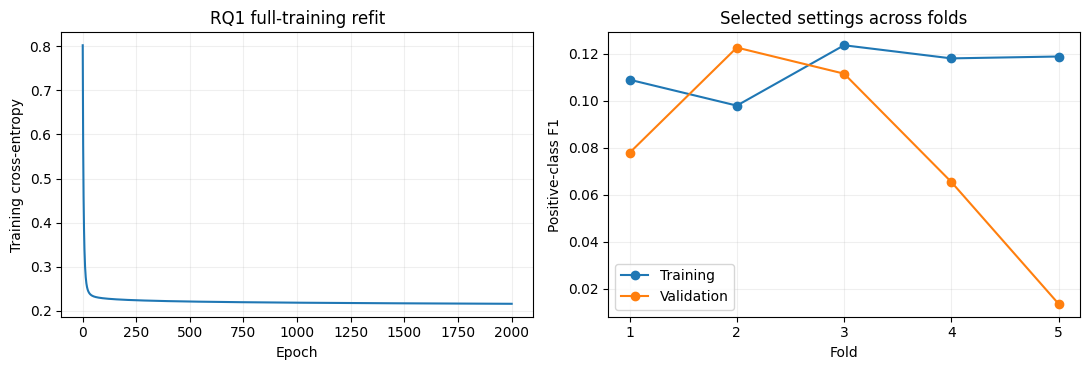

Training loss changed from 0.8021 to 0.2160 over 2000 epochs. The refit reached the epoch limit and did not meet the loss-based stopping criterion. 6 of the 40 search fits reported a convergence warning. These diagnostics limit claims about optimisation.

In [73]:
c_rq1_model, c_refit_warnings = fit_pipeline(
    preprocessor_rq1, c_model, c_best_settings, X_train_rq1, y_train
)
c_fitted = c_rq1_model.named_steps["model"]
c_diagnostics = pd.DataFrame([{
    "Experiment": "RQ1", "Input features": c_fitted.n_features_in_,
    "Epochs": c_fitted.n_iter_, "Initial loss": c_fitted.loss_curve_[0],
    "Final loss": c_fitted.loss_curve_[-1],
    "CV convergence warnings": int(c_best_folds["Convergence warnings"].sum()),
    "Refit convergence warnings": len(c_refit_warnings),
}])
display(c_diagnostics.round(5))
for message in sorted(set(c_refit_warnings)):
    print("ConvergenceWarning:", message)

c_training_figure, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(range(1, c_fitted.n_iter_ + 1), c_fitted.loss_curve_)
axes[0].set(xlabel="Epoch", ylabel="Training cross-entropy", title="RQ1 full-training refit")
axes[1].plot(c_best_folds["Fold"], c_best_folds["Training F1"], "o-", label="Training")
axes[1].plot(c_best_folds["Fold"], c_best_folds["F1"], "o-", label="Validation")
axes[1].set(xlabel="Fold", ylabel="Positive-class F1", title="Selected settings across folds")
axes[1].set_xticks(range(1, len(cv_splits) + 1))
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
c_training_figure.tight_layout()
plt.show()

c_stop_note = ("The refit reached the epoch limit and did not meet the loss-based "
               "stopping criterion." if c_refit_warnings else
               "The refit met the configured loss-based stopping criterion; this "
               "does not guarantee a global optimum.")
display(Markdown(
    f"Training loss changed from {c_fitted.loss_curve_[0]:.4f} to "
    f"{c_fitted.loss_curve_[-1]:.4f} over {c_fitted.n_iter_} epochs. {c_stop_note} "
    f"{int(c_tuning['Convergence warnings'].sum())} of the {len(c_candidates) * N_SPLITS} search fits "
    "reported a convergence warning. These diagnostics limit claims about optimisation."
))


## 16. Primary Neural-network Experiments

### 16.1 RQ1 Model Comparison

The gradient-descent MLP is compared with the three classical models and Zero-R
using identical RQ1 test rows. The table is ordered by mean validation F1, the
selection criterion. Held-out test metrics include Accuracy, Precision, Recall,
F1 and ROC-AUC, enabling a consistent comparison of predictive performance.

In [74]:
c_rq1_prediction = predict_at_threshold(c_rq1_model, X_test_rq1, c_best_threshold)
c_rq1_metrics = c_metrics(y_test, c_rq1_prediction, c_positive_score(c_rq1_model, X_test_rq1))
c_baseline = DummyClassifier(strategy="most_frequent").fit(X_train_rq1, y_train)
c_baseline_metrics = c_metrics(y_test, c_baseline.predict(X_test_rq1), c_positive_score(c_baseline, X_test_rq1))
c_rq1_rows = []
for name, cv_f1, values in [
    ("Logistic Regression", best_lr_f1, lr_test_metrics),
    ("Decision Tree", best_dt_f1, dt_test_metrics),
    ("Linear SVM", best_svm_f1, svm_test_metrics),
    ("MLP (gradient descent)", c_selected["CV F1"], c_rq1_metrics),
    ("Zero-R", 0.0, c_baseline_metrics),
]:
    c_rq1_rows.append({"Model": name, "Mean CV F1": cv_f1,
                       **{"Test " + m: values[m] for m in c_metric_names}})
c_rq1_comparison = pd.DataFrame(c_rq1_rows).sort_values(
    "Mean CV F1", ascending=False, kind="stable"
).reset_index(drop=True)
display(c_rq1_comparison.round(4))

c_rq1_cm = confusion_matrix(y_test, c_rq1_prediction, labels=[0, 1])
display(pd.DataFrame(c_rq1_cm, index=["Actual no", "Actual yes"],
                     columns=["Predicted no", "Predicted yes"]))
c_tn, c_fp, c_fn, c_tp = c_rq1_cm.ravel()
display(Markdown(
    f"The MLP obtains test F1 **{c_rq1_metrics['F1']:.4f}**, precision "
    f"{c_rq1_metrics['Precision']:.4f}, recall {c_rq1_metrics['Recall']:.4f}, "
    f"and ROC-AUC **{c_rq1_metrics['ROC-AUC']:.4f}**. "
    f"It identifies {c_tp} of {c_tp + c_fn} subscribers, misses {c_fn}, and "
    f"incorrectly flags {c_fp} non-subscribers. Zero-R misses every subscriber. "
    f"The highest mean validation F1 in this table belongs to "
    f"**{c_rq1_comparison.iloc[0]['Model']}**; test differences on this split "
    "alone do not establish consistent superiority."
))


# Same fitted model: isolate the effect of its selected threshold (no extra fitting).
threshold_rows = []
for name, pipeline, threshold in [
    ("Logistic Regression", best_lr_pipeline, best_lr_threshold),
    ("Decision Tree", best_dt_pipeline, best_dt_threshold),
    ("Linear SVM", best_svm_pipeline, best_svm_threshold),
    ("MLP (gradient descent)", c_rq1_model, c_best_threshold),
]:
    score = positive_score(pipeline, X_test_rq1)
    chosen = (score > threshold).astype(int)
    threshold_rows.append({
        "Model": name, "Threshold": threshold,
        "Default-threshold F1": f1_score(y_test, pipeline.predict(X_test_rq1)),
        "Selected-threshold F1": f1_score(y_test, chosen),
        "Predicted yes rate": chosen.mean(),
    })
display(pd.DataFrame(threshold_rows).round(4))
all_yes_metrics = evaluate_model(y_test, np.ones(len(y_test), dtype=int), np.ones(len(y_test)))
print("Constant-yes diagnostic (not Zero-R):", all_yes_metrics)
print("Compare model F1 with constant-yes F1; higher recall alone need not imply useful discrimination.")


# A simple additional check: high F1 need not imply useful ranking.
all_yes_cv_f1 = np.mean([
    f1_score(y_train.iloc[val_pos], np.ones(len(val_pos), dtype=int))
    for _, val_pos in cv_splits
])
print(f"Constant-yes mean validation F1: {all_yes_cv_f1:.4f}")
below_reference = c_rq1_comparison.loc[
    (c_rq1_comparison["Model"] != "Zero-R")
    & (c_rq1_comparison["Mean CV F1"] <= all_yes_cv_f1), "Model"
].tolist()
print("Selected models not exceeding constant-yes mean validation F1:", below_reference)
below_test_reference = c_rq1_comparison.loc[
    (c_rq1_comparison["Model"] != "Zero-R")
    & (c_rq1_comparison["Test F1"] <= all_yes_metrics["F1"]), "Model"
].tolist()
print("Selected models not exceeding constant-yes test F1:", below_test_reference)
print("F1 should be interpreted alongside precision, recall and the constant-yes reference.")


,Model,Mean CV F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Linear SVM,0.1590,0.4082,0.3283,0.8795,0.4782,0.6363
1,Decision Tree,0.1268,0.3721,0.3208,0.9279,0.4768,0.5571
2,Logistic Regression,0.0815,0.3864,0.3317,0.9760,0.4951,0.7479
3,MLP (gradient descent),0.0782,0.4550,0.3328,0.7641,0.4636,0.6442
4,Zero-R,0.0000,0.6917,0.0000,0.0000,0.0000,0.5000


,Predicted no,Predicted yes
Actual no,1807,3890
Actual yes,599,1940


The MLP obtains test F1 **0.4636**, precision 0.3328, recall 0.7641, and ROC-AUC **0.6442**. It identifies 1940 of 2539 subscribers, misses 599, and incorrectly flags 3890 non-subscribers. Zero-R misses every subscriber. The highest mean validation F1 in this table belongs to **Linear SVM**; test differences on this split alone do not establish consistent superiority.

,Model,Threshold,Default-threshold F1,Selected-threshold F1,Predicted yes rate
0,Logistic Regression,0.05,0.4400,0.4951,0.9071
1,Decision Tree,0.05,0.1369,0.4768,0.8917
2,Linear SVM,-1.00,0.2438,0.4782,0.8258
3,MLP (gradient descent),0.05,0.2147,0.4636,0.7079


Constant-yes diagnostic (not Zero-R): {'Accuracy': 0.3082807187955318, 'Precision': 0.3082807187955318, 'Recall': 1.0, 'F1': 0.47127610208816706, 'ROC-AUC': 0.5}
Compare model F1 with constant-yes F1; higher recall alone need not imply useful discrimination.


Constant-yes mean validation F1: 0.1300
Selected models not exceeding constant-yes mean validation F1: ['Decision Tree', 'Logistic Regression', 'MLP (gradient descent)']
Selected models not exceeding constant-yes test F1: ['MLP (gradient descent)']
F1 should be interpreted alongside precision, recall and the constant-yes reference.


### 16.2 RQ2: Added Value of Previous Campaign History

The RQ1-selected hidden width, learning rate, stopping settings and probability threshold are fixed for both feature sets. No RQ2 MLP parameter or threshold is selected from test labels.
Set A contains demographic/financial information; Set B adds the four history
features from Section 6. Each model is trained separately, using the same folds,
stopping rule and prediction rule. Input width and learned weights necessarily
differ. The comparison measures predictive value, not a causal effect of contact.


In [75]:
c_rq2_sets = {
    "Set A": (X_train_without, X_test_without, preprocessor_without),
    "Set B": (X_train_with, X_test_with, preprocessor_with),
}
c_rq2_models = {}
c_rq2_predictions = {}
c_rq2_fold_rows = []
c_rq2_rows = []
c_rq2_diagnostic_rows = []

for set_name, (X_train_set, X_test_set, preprocessor) in c_rq2_sets.items():
    assert X_train_set.index.equals(y_train.index)
    assert X_test_set.index.equals(y_test.index)
    for fold, (fit_pos, val_pos) in enumerate(cv_splits, start=1):
        pipeline, messages = fit_pipeline(
            preprocessor, c_model, c_best_settings,
            X_train_set.iloc[fit_pos], y_train.iloc[fit_pos]
        )
        c_rq2_fold_rows.append({
            "Feature set": set_name, "Fold": fold,
            **c_metrics(y_train.iloc[val_pos], predict_at_threshold(pipeline, X_train_set.iloc[val_pos], c_best_threshold),
                        c_positive_score(pipeline, X_train_set.iloc[val_pos])),
            "Training F1": f1_score(y_train.iloc[fit_pos], predict_at_threshold(pipeline, X_train_set.iloc[fit_pos], c_best_threshold)),
            "Epochs": pipeline.named_steps["model"].n_iter_,
            "Convergence warnings": len(messages),
        })
        print(f"{set_name}, fold={fold}: F1={c_rq2_fold_rows[-1]['F1']:.4f}, "
              f"warnings={len(messages)}", flush=True)

    pipeline, messages = fit_pipeline(
        preprocessor, c_model, c_best_settings, X_train_set, y_train
    )
    c_rq2_models[set_name] = pipeline
    prediction = predict_at_threshold(pipeline, X_test_set, c_best_threshold)
    c_rq2_predictions[set_name] = prediction
    rows = pd.DataFrame([r for r in c_rq2_fold_rows if r["Feature set"] == set_name])
    c_rq2_rows.append({
        "Feature set": set_name,
        "CV F1": rows["F1"].mean(), "CV F1 SD": rows["F1"].std(ddof=0),
        "CV ROC-AUC": rows["ROC-AUC"].mean(),
        "CV ROC-AUC SD": rows["ROC-AUC"].std(ddof=0),
        "Training F1": rows["Training F1"].mean(),
        **{"Test " + k: v for k, v in c_metrics(y_test, prediction, c_positive_score(pipeline, X_test_set)).items()},
    })
    model = pipeline.named_steps["model"]
    c_rq2_diagnostic_rows.append({
        "Feature set": set_name, "Input features": model.n_features_in_,
        "Refit epochs": model.n_iter_,
        "CV convergence warnings": rows["Convergence warnings"].sum(),
        "Refit convergence warnings": len(messages),
    })
    for message in sorted(set(messages)):
        print(set_name, "ConvergenceWarning:", message)

c_rq2_folds = pd.DataFrame(c_rq2_fold_rows)
c_rq2_results = pd.DataFrame(c_rq2_rows).set_index("Feature set")
c_rq2_diagnostics = pd.DataFrame(c_rq2_diagnostic_rows)
display(c_rq2_results.round(4))
display(c_rq2_diagnostics)
c_rq2_delta = c_rq2_results.loc["Set B"] - c_rq2_results.loc["Set A"]
display(c_rq2_delta[["CV F1", "CV ROC-AUC", "Test Accuracy", "Test Precision", "Test Recall", "Test F1", "Test ROC-AUC"]]
        .rename("Set B minus Set A").to_frame().round(4))
c_rq2_paired = c_rq2_folds.pivot(index="Fold", columns="Feature set", values="F1")
c_rq2_paired["B minus A"] = c_rq2_paired["Set B"] - c_rq2_paired["Set A"]
display(c_rq2_paired.round(4))
display(Markdown(
    f"Adding history changes test F1 from **{c_rq2_results.loc['Set A', 'Test F1']:.4f}** "
    f"to **{c_rq2_results.loc['Set B', 'Test F1']:.4f}** "
    f"(difference {c_rq2_delta['Test F1']:+.4f}). Mean validation F1 changes by "
    f"{c_rq2_delta['CV F1']:+.4f}, and Set B scores higher in "
    f"{int((c_rq2_paired['B minus A'] > 0).sum())} of five folds. "
    f"Test recall changes by {c_rq2_delta['Test Recall']:+.4f}. "
    f"Test ROC-AUC changes from **{c_rq2_results.loc['Set A', 'Test ROC-AUC']:.4f}** "
    f"to **{c_rq2_results.loc['Set B', 'Test ROC-AUC']:.4f}** "
    f"(difference {c_rq2_delta['Test ROC-AUC']:+.4f}). "
    "The result is conditional on the fixed configuration; it does not compare "
    "independently optimised feature sets or establish causality."
))

# Final RQ2 comparison: one neural-network version only.
c_rq2_nn_summary = c_rq2_results.reset_index().rename(columns={
    "Feature set": "Feature Set", "CV F1": "Mean CV F1",
    **{"Test " + m: m for m in c_metric_names},
}).assign(**{
    "Model": "MLP (gradient descent)",
    "Tuning Strategy": "Fixed RQ1 configuration + threshold",
})
c_rq2_comparison = pd.concat([
    rq2_results, c_rq2_nn_summary[rq2_results.columns]
], ignore_index=True)
display(Markdown("#### Canonical final RQ2 Set A / Set B comparison"))
display(c_rq2_comparison.round(4))

# Canonical final RQ2 delta table, calculated from full-precision test results.
rq2_final_delta_rows = []
for model_name in [
    "Logistic Regression", "Decision Tree",
    "Linear SVM", "MLP (gradient descent)"
]:
    model_results = c_rq2_comparison[
        c_rq2_comparison["Model"] == model_name
    ].set_index("Feature Set")
    rq2_final_delta_rows.append({
        "Model": model_name,
        **{
            "Δ " + metric: (
                model_results.loc["Set B", metric]
                - model_results.loc["Set A", metric]
            )
            for metric in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
        }
    })

rq2_final_delta_table = pd.DataFrame(rq2_final_delta_rows)
display(Markdown(
    "#### Canonical final RQ2 Set B − Set A differences\n"
    "Positive values mean Set B performed better than Set A. "
    "Values are absolute metric differences, not percentage changes."
))
display(rq2_final_delta_table.round(4))


print("RQ2 shares the same constant-yes test diagnostic:", all_yes_metrics)


Set A, fold=1: F1=0.0302, warnings=1
Set A, fold=2: F1=0.0572, warnings=0
Set A, fold=3: F1=0.0812, warnings=0
Set A, fold=4: F1=0.0966, warnings=0
Set A, fold=5: F1=0.2320, warnings=0
Set B, fold=1: F1=0.0235, warnings=0
Set B, fold=2: F1=0.0668, warnings=0
Set B, fold=3: F1=0.0705, warnings=0
Set B, fold=4: F1=0.0992, warnings=0
Set B, fold=5: F1=0.2573, warnings=0


,CV F1,CV F1 SD,CV ROC-AUC,CV ROC-AUC SD,Training F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
Feature set,,,,,,,,,,
Set A,0.0994,0.0700,0.5158,0.0200,0.0828,0.3633,0.3218,0.9618,0.4822,0.5874
Set B,0.1035,0.0807,0.5178,0.0355,0.0769,0.3814,0.3270,0.9516,0.4868,0.6935


,Feature set,Input features,Refit epochs,CV convergence warnings,Refit convergence warnings
0,Set A,34,1844,1,0
1,Set B,40,1820,0,0


,Set B minus Set A
CV F1,0.0040
CV ROC-AUC,0.0021
Test Accuracy,0.0181
Test Precision,0.0052
Test Recall,-0.0102
Test F1,0.0045
Test ROC-AUC,0.1061


Feature set,Set A,Set B,B minus A
Fold,,,
1,0.0302,0.0235,-0.0067
2,0.0572,0.0668,0.0096
3,0.0812,0.0705,-0.0107
4,0.0966,0.0992,0.0026
5,0.2320,0.2573,0.0254


...

#### Canonical final RQ2 Set A / Set B comparison

,Model,Feature Set,Tuning Strategy,Mean CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Set A,Separate search per feature set,0.1104,0.3533,0.3176,0.9559,0.4768,0.5773
1,Logistic Regression,Set B,Separate search per feature set,0.1155,0.3680,0.3230,0.9579,0.4831,0.6850
2,Decision Tree,Set A,Separate search per feature set,0.1230,0.3919,0.3221,0.8807,0.4717,0.5760
3,Decision Tree,Set B,Separate search per feature set,0.1249,0.4161,0.3324,0.8866,0.4835,0.6621
4,Linear SVM,Set A,Separate search per feature set,0.1320,0.3865,0.3014,0.7511,0.4301,0.5115
5,Linear SVM,Set B,Separate search per feature set,0.1300,0.3083,0.3083,1.0000,0.4713,0.5959
6,MLP (gradient descent),Set A,Fixed RQ1 configuration + threshold,0.0994,0.3633,0.3218,0.9618,0.4822,0.5874
7,MLP (gradient descent),Set B,Fixed RQ1 configuration + threshold,0.1035,0.3814,0.3270,0.9516,0.4868,0.6935


#### Canonical final RQ2 Set B − Set A differences
Positive values mean Set B performed better than Set A. Values are absolute metric differences, not percentage changes.

,Model,Δ Accuracy,Δ Precision,Δ Recall,Δ F1,Δ ROC-AUC
0,Logistic Regression,0.0147,0.0053,0.0020,0.0062,0.1077
1,Decision Tree,0.0242,0.0103,0.0059,0.0118,0.0861
2,Linear SVM,-0.0782,0.0069,0.2489,0.0411,0.0845
3,MLP (gradient descent),0.0181,0.0052,-0.0102,0.0045,0.1061


RQ2 shares the same constant-yes test diagnostic: {'Accuracy': 0.3082807187955318, 'Precision': 0.3082807187955318, 'Recall': 1.0, 'F1': 0.47127610208816706, 'ROC-AUC': 0.5}


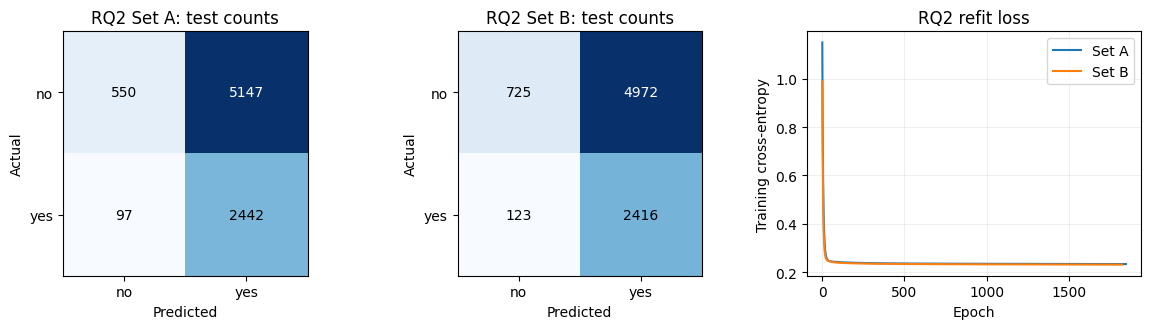

In [76]:
c_history_figure, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, set_name in zip(axes[:2], ["Set A", "Set B"]):
    cm = confusion_matrix(y_test, c_rq2_predictions[set_name], labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for row in range(2):
        for col in range(2):
            ax.text(col, row, str(cm[row, col]), ha="center", va="center",
                    color="white" if cm[row, col] > cm.max() / 2 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["no", "yes"],
           yticklabels=["no", "yes"], xlabel="Predicted", ylabel="Actual",
           title=f"RQ2 {set_name}: test counts")
for set_name, pipeline in c_rq2_models.items():
    losses = pipeline.named_steps["model"].loss_curve_
    axes[2].plot(range(1, len(losses) + 1), losses, label=set_name)
axes[2].set(xlabel="Epoch", ylabel="Training cross-entropy", title="RQ2 refit loss")
axes[2].legend()
axes[2].grid(alpha=0.2)
c_history_figure.tight_layout()
plt.show()

### 16.3 Error Analysis

The following examples are the first two false negatives and false positives in
test-row order, rather than hand-picked cases. Actual and predicted labels are
shown beside available features. The group table checks whether adding history
changes recall across prior campaign outcomes; group counts matter when interpreting
small subgroups. These test observations are not used for further tuning.

In [77]:
c_error_cases = X_test_rq1[["age", "job", "education", "previous", "poutcome"]].copy()
c_error_cases["Actual"] = y_test
c_error_cases["Predicted"] = c_rq1_prediction
c_error_cases["P(yes)"] = c_rq1_model.predict_proba(X_test_rq1)[:, 1]
c_error_cases["Error"] = np.select(
    [(c_error_cases["Actual"] == 1) & (c_error_cases["Predicted"] == 0),
     (c_error_cases["Actual"] == 0) & (c_error_cases["Predicted"] == 1)],
    ["False negative", "False positive"], default="Correct"
)
c_examples = pd.concat([
    c_error_cases[c_error_cases["Error"] == label].head(2)
    for label in ["False negative", "False positive"]
])
display(c_examples.round(4))

c_group_rows = []
for outcome in sorted(X_test_with["poutcome"].unique()):
    mask = X_test_with["poutcome"].eq(outcome).to_numpy()
    actual = y_test.to_numpy()[mask]
    positives = int(actual.sum())
    a_pred = c_rq2_predictions["Set A"][mask]
    b_pred = c_rq2_predictions["Set B"][mask]
    c_group_rows.append({
        "Previous outcome": outcome, "Test observations": int(mask.sum()),
        "Actual subscribers": positives,
        "Set A recall": recall_score(actual, a_pred, zero_division=0) if positives else np.nan,
        "Set B recall": recall_score(actual, b_pred, zero_division=0) if positives else np.nan,
        "Set A false positives": int(((actual == 0) & (a_pred == 1)).sum()),
        "Set B false positives": int(((actual == 0) & (b_pred == 1)).sum()),
    })
c_history_groups = pd.DataFrame(c_group_rows)
display(c_history_groups.round(4))

# Explain one concrete error and, when present, a subscriber recovered by history.
c_fn_examples = c_error_cases[c_error_cases["Error"] == "False negative"]
if not c_fn_examples.empty:
    row_id = c_fn_examples.index[0]
    example = c_fn_examples.iloc[0]
    outcome = example["poutcome"]
    train_mask = X_train_rq1["poutcome"].eq(outcome)
    group_rate = y_train.loc[train_mask].mean()
    display(Markdown(
        f"Test row **{row_id}** is a subscriber but receives P(yes)="
        f"{example['P(yes)']:.4f}, at or below the selected {c_best_threshold:g} decision threshold. "
        f"Its previous outcome is **{outcome}**. In the training data, "
        f"{group_rate:.1%} of records with that outcome are subscribers. "
        "This illustrates a missed minority-class case; the group frequency "
        "describes context and does not prove which feature caused this prediction."
    ))

c_recovered = ((y_test.to_numpy() == 1)
               & (c_rq2_predictions["Set A"] == 0)
               & (c_rq2_predictions["Set B"] == 1))
if c_recovered.any():
    position = int(np.flatnonzero(c_recovered)[0])
    row_id = y_test.index[position]
    prob_a = c_rq2_models["Set A"].predict_proba(X_test_without.iloc[[position]])[0, 1]
    prob_b = c_rq2_models["Set B"].predict_proba(X_test_with.iloc[[position]])[0, 1]
    outcome = X_test_with.iloc[position]["poutcome"]
    display(Markdown(
        f"For RQ2, subscriber **{row_id}** is missed by Set A "
        f"(P(yes)={prob_a:.4f}) and correctly identified by Set B "
        f"(P(yes)={prob_b:.4f}); the previous outcome is **{outcome}**. "
        "The added history features allow a different decision for this case, "
        "although the comparison does not attribute it to one history feature alone."
    ))
else:
    display(Markdown("No test subscriber missed by Set A is recovered by Set B "
                     "under this configuration."))


,age,job,education,previous,poutcome,Actual,Predicted,P(yes),Error
32978,39,blue-collar,basic.6y,0,nonexistent,1,0,0.0321,False negative
33025,27,blue-collar,basic.4y,0,nonexistent,1,0,0.0199,False negative
32941,31,technician,university.degree,1,failure,0,1,0.0638,False positive
32943,28,blue-collar,professional.course,0,nonexistent,0,1,0.0842,False positive


,Previous outcome,Test observations,Actual subscribers,Set A recall,Set B recall,Set A false positives,Set B false positives
0,failure,2145,480,0.9542,0.9083,1493,1374
1,nonexistent,4886,1228,0.9520,0.9357,3297,3224
2,success,1205,831,0.9807,1.0000,357,374


Test row **32978** is a subscriber but receives P(yes)=0.0321, at or below the selected 0.05 decision threshold. Its previous outcome is **nonexistent**. In the training data, 6.2% of records with that outcome are subscribers. This illustrates a missed minority-class case; the group frequency describes context and does not prove which feature caused this prediction.

For RQ2, subscriber **33332** is missed by Set A (P(yes)=0.0481) and correctly identified by Set B (P(yes)=0.0577); the previous outcome is **failure**. The added history features allow a different decision for this case, although the comparison does not attribute it to one history feature alone.

## 17. Primary Findings and Limitations

The validation and test tables answer RQ1 under the shared split and identify the
precision–recall trade-off. The fixed-configuration Set A/Set B experiment answers
RQ2 by measuring the additional predictive information in campaign history.
The selected model is discussed below using the observed errors and validation gap.

In [78]:
c_recall_gain = c_history_groups["Set B recall"] - c_history_groups["Set A recall"]
c_largest_group = c_history_groups.loc[c_recall_gain.idxmax()]
c_capacity_best = c_tuning.groupby("Hidden neurons")["CV F1"].max()
c_capacity_change = c_capacity_best.loc[32] - c_capacity_best.loc[16]
display(Markdown(
    f"Increasing hidden width from 16 to 32 changes the best validation F1 across "
    f"the searched learning rates, stopping settings and thresholds by {c_capacity_change:+.4f}. This illustrates that "
    "extra capacity must be assessed on validation data. "
    f"The selected model's training–validation F1 gap is {c_gap:.4f}; "
    f"the validation-fold SD is {c_selected['CV F1 SD']:.4f}. "
    "With chronological validation, this gap can reflect both overfitting and "
    "temporal distribution shift. Recall and the classical-model comparison "
    "also matter when judging usefulness."
))
display(Markdown(
    f"For RQ2, the largest observed recall change (Set B minus Set A) is in the "
    f"**{c_largest_group['Previous outcome']}** group "
    f"({int(c_largest_group['Actual subscribers'])} actual subscribers): "
    f"{c_largest_group['Set A recall']:.4f} to {c_largest_group['Set B recall']:.4f}. "
    "A positive change indicates improved detection in this group; a zero or "
    "negative change does not. This descriptive comparison does not isolate "
    "a single feature's effect."
))

c_smallest_group = c_history_groups.loc[c_recall_gain.idxmin()]
display(Markdown(
    f"The smallest recall change is in the **{c_smallest_group['Previous outcome']}** group. It "
    f"has {int(c_smallest_group['Actual subscribers'])} subscribers, and recall "
    f"changes from {c_smallest_group['Set A recall']:.4f} to "
    f"{c_smallest_group['Set B recall']:.4f}. Aggregate scores should be interpreted "
    "alongside these group-specific changes."
))


Increasing hidden width from 16 to 32 changes the best validation F1 across the searched learning rates, stopping settings and thresholds by +0.0068. This illustrates that extra capacity must be assessed on validation data. The selected model's training–validation F1 gap is 0.0353; the validation-fold SD is 0.0385. With chronological validation, this gap can reflect both overfitting and temporal distribution shift. Recall and the classical-model comparison also matter when judging usefulness.

For RQ2, the largest observed recall change (Set B minus Set A) is in the **success** group (831 actual subscribers): 0.9807 to 1.0000. A positive change indicates improved detection in this group; a zero or negative change does not. This descriptive comparison does not isolate a single feature's effect.

The smallest recall change is in the **failure** group. It has 480 subscribers, and recall changes from 0.9542 to 0.9083. Aggregate scores should be interpreted alongside these group-specific changes.

The experiment uses one chronological 80/20 holdout and one initialisation seed.
Expanding-window validation respects the original row order but covers unequal
calendar durations. Class proportions and other features can shift over time, so
performance on this later block does not guarantee performance on future campaigns.
Exact timestamps and client identifiers are unavailable; same-date or repeated-client
separation cannot be guaranteed from row order alone. Test results were inspected during development, so this evaluation is exploratory.

The limited parameter grid and any convergence warnings further restrict conclusions. The reported best CV F1 is a tuning score from the same folds used to choose parameters and thresholds, not an unbiased independent performance estimate. Lower thresholds can improve F1 while reducing precision or accuracy; a constant-yes diagnostic is included to reveal trivial high-recall behaviour.
RQ2 fixes MLP hidden width, training rules and decision threshold, but adding inputs changes the number
of weights. Classical RQ2 models are tuned separately per feature set, so their
changes also reflect configuration selection. Full-dataset exploratory summaries
are descriptive and do not provide independent test evidence.


### 17.1 Related Work and Sources

Moro et al. (2014) study bank telemarketing prediction and motivate this dataset and
task; their published results are not directly comparable to this feature definition
and split. Rumelhart et al. (1986) provide the backpropagation learning method.
Hornik et al. (1989) establish approximation results under squashing-activation
assumptions. This motivates separating representational capacity from empirical
performance; it does not prove optimality for the finite ReLU networks used here.

- Moro, S., Cortez, P., and Rita, P. (2014). *A data-driven approach to predict the
  success of bank telemarketing*. Decision Support Systems, 62, 22–31.
  https://doi.org/10.1016/j.dss.2014.03.001
- Rumelhart, D. E., Hinton, G. E., and Williams, R. J. (1986).
  *Learning representations by back-propagating errors*. Nature, 323, 533–536.
  https://doi.org/10.1038/323533a0
- Hornik, K., Stinchcombe, M., and White, H. (1989). *Multilayer feedforward networks
  are universal approximators*. Neural Networks, 2(5), 359–366.
  https://doi.org/10.1016/0893-6080(89)90020-8
- Data: UCI Bank Marketing, `bank-additional-full.csv`, 41,188 rows before duplicate
  removal. https://archive.ics.uci.edu/dataset/222/bank+marketing
- Implementation: scikit-learn [decision thresholds](https://scikit-learn.org/stable/modules/classification_threshold.html), and `MLPClassifier` documentation.
  https://scikit-learn.org/1.8/modules/generated/sklearn.neural_network.MLPClassifier.html
